# SVD: Layer 1 — current controlled results
Paths and input adapters updated; original plotting and average-count metric retained.
Current recommendation size: 20. Baseline and Drama/Thriller injections: 2, 4, 6, 25, 50, 100, 200, 500, 1000, 2000.
Saved without execution or retraining. Original historical result files under result/nmf and result/svd are unchanged.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt

### bar analysis_SVD

In [ ]:
from pathlib import Path
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path("/home/moshtasa/Research/phd-recsys/Book/current/PerturbRec/svd_nmf/layer1")
MODEL = "svd"
OUT_BASE = ROOT / "result" / MODEL.upper() / "bar_figures"
OUT_BASE.mkdir(parents=True, exist_ok=True)
# Same metric as the original notebook: mean target-genre count per real user.
# The controlled analysis already stores this mean for top-20 unseen recommendations.
summary = pd.read_csv(ROOT / "tables/controlled_recommendation_summary.csv")
summary = summary[summary.model == MODEL]
results = defaultdict(lambda: defaultdict(dict))
for genre, rows in summary.groupby("genre"):
    assert rows.target_count_baseline.nunique() == 1
    results[genre][20]["original"] = (rows.target_count_baseline.iloc[0], int(rows.n_users.iloc[0]))
    for row in rows.itertuples():
        results[genre][20][f"{row.n_fake}u"] = (row.target_count_after, int(row.n_users))

# =========================
# COLORS (FINAL STYLE PALETTE)
# =========================

def generate_colors(n_list):
    palette = [
        "#4E79A7", "#59A14F", "#E15759", "#B07AA1",
        "#F28E2B", "#76B7B2", "#EDC948", "#9C755F",
        "#FF9DA7", "#8CD17D", "#86BCB6", "#BAB0AC"
    ]
    return {n: palette[i % len(palette)] for i, n in enumerate(n_list)}

# =========================
# PLOTTING
# =========================

for genre, k_data in results.items():

    ks = sorted(k_data.keys())

    n_types = sorted(set(
        n for k in ks for n in k_data[k].keys()
    ), key=lambda x: (x != "original", int(x.replace("u", "")) if x != "original" else -1))

    color_map = generate_colors(n_types)

    x = np.arange(len(ks)) * 1.2
    width = 1.0 / len(n_types)

    fig, ax = plt.subplots(figsize=(18, 11))

    max_val = 0
    bar_containers = []

    for i, n in enumerate(n_types):
        vals = [k_data[k].get(n, (0, 0))[0] for k in ks]

        bars = ax.bar(
            x + (i - len(n_types)/2) * width + width/2,
            vals,
            width=width,
            color=color_map[n],
            edgecolor="black",
            linewidth=0.6,
            label=n
        )

        bar_containers.append((bars, vals))
        max_val = max(max_val, max(vals))

    # =========================
    # STYLE (UPDATED)
    # =========================

    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)

    ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

    ax.set_title(f"SVD - {genre}", fontsize=40, fontweight="bold", pad=20)
    ax.set_xlabel("k (recommendation size)", fontsize=38, labelpad=14)
    ax.set_ylabel("Avg count per user", fontsize=38, labelpad=14)

    ax.set_xticks(x)
    ax.set_xticklabels(ks, fontsize=34)
    ax.tick_params(axis='y', labelsize=34)

    ax.legend(fontsize=22, ncol=3)

    # =========================
    # BAR LABELS
    # =========================

    for bars, vals in bar_containers:
        for bar, val in zip(bars, vals):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                val + max_val * 0.015,
                f"{val:.2f}",
                ha="center",
                va="bottom",
                fontsize=22,
                rotation=90,
            )

    ax.set_ylim(top=max_val * 1.25)

    # =========================
    # SAVE FIGURE
    # =========================

    genre_folder = OUT_BASE / f"SVD_{genre.lower().replace(' ', '_')}_analysis"
    genre_folder.mkdir(parents=True, exist_ok=True)

    fig_path = genre_folder / f"SVD - {genre}.png"

    plt.tight_layout()
    plt.savefig(fig_path, dpi=300)
    plt.close()

    # =========================
    # SAVE EXPLANATION TEXT
    # =========================

    explanation_path = genre_folder / f"SVD - {genre}.txt"

    with open(explanation_path, "w") as f:
        f.write(f"SVD Analysis for Genre: {genre}\n\n")
        f.write("Metric: Average count of target genre per user\n\n")

        for k in ks:
            f.write(f"k = {k}\n")
            for n in n_types:
                val, users = k_data[k].get(n, (0, 0))
                f.write(f"  {n}: {val:.4f} (users={users})\n")
            f.write("\n")

print("All SVD figures and explanation files saved.")

### Controlled bias and mean-rating analysis
Baseline and all injection sizes through 3,000, for Drama and Thriller.
The existing 2,000-user CSV files also contain 2,500 and 3,000 rows, distinguished by `n_fake`.
Charts are embedded here and saved as PNGs in the existing model result folder, under MODEL_details_figures/Drama or Thriller.
Groups are based on any rated-book genre, not demonstrated positive preferences.


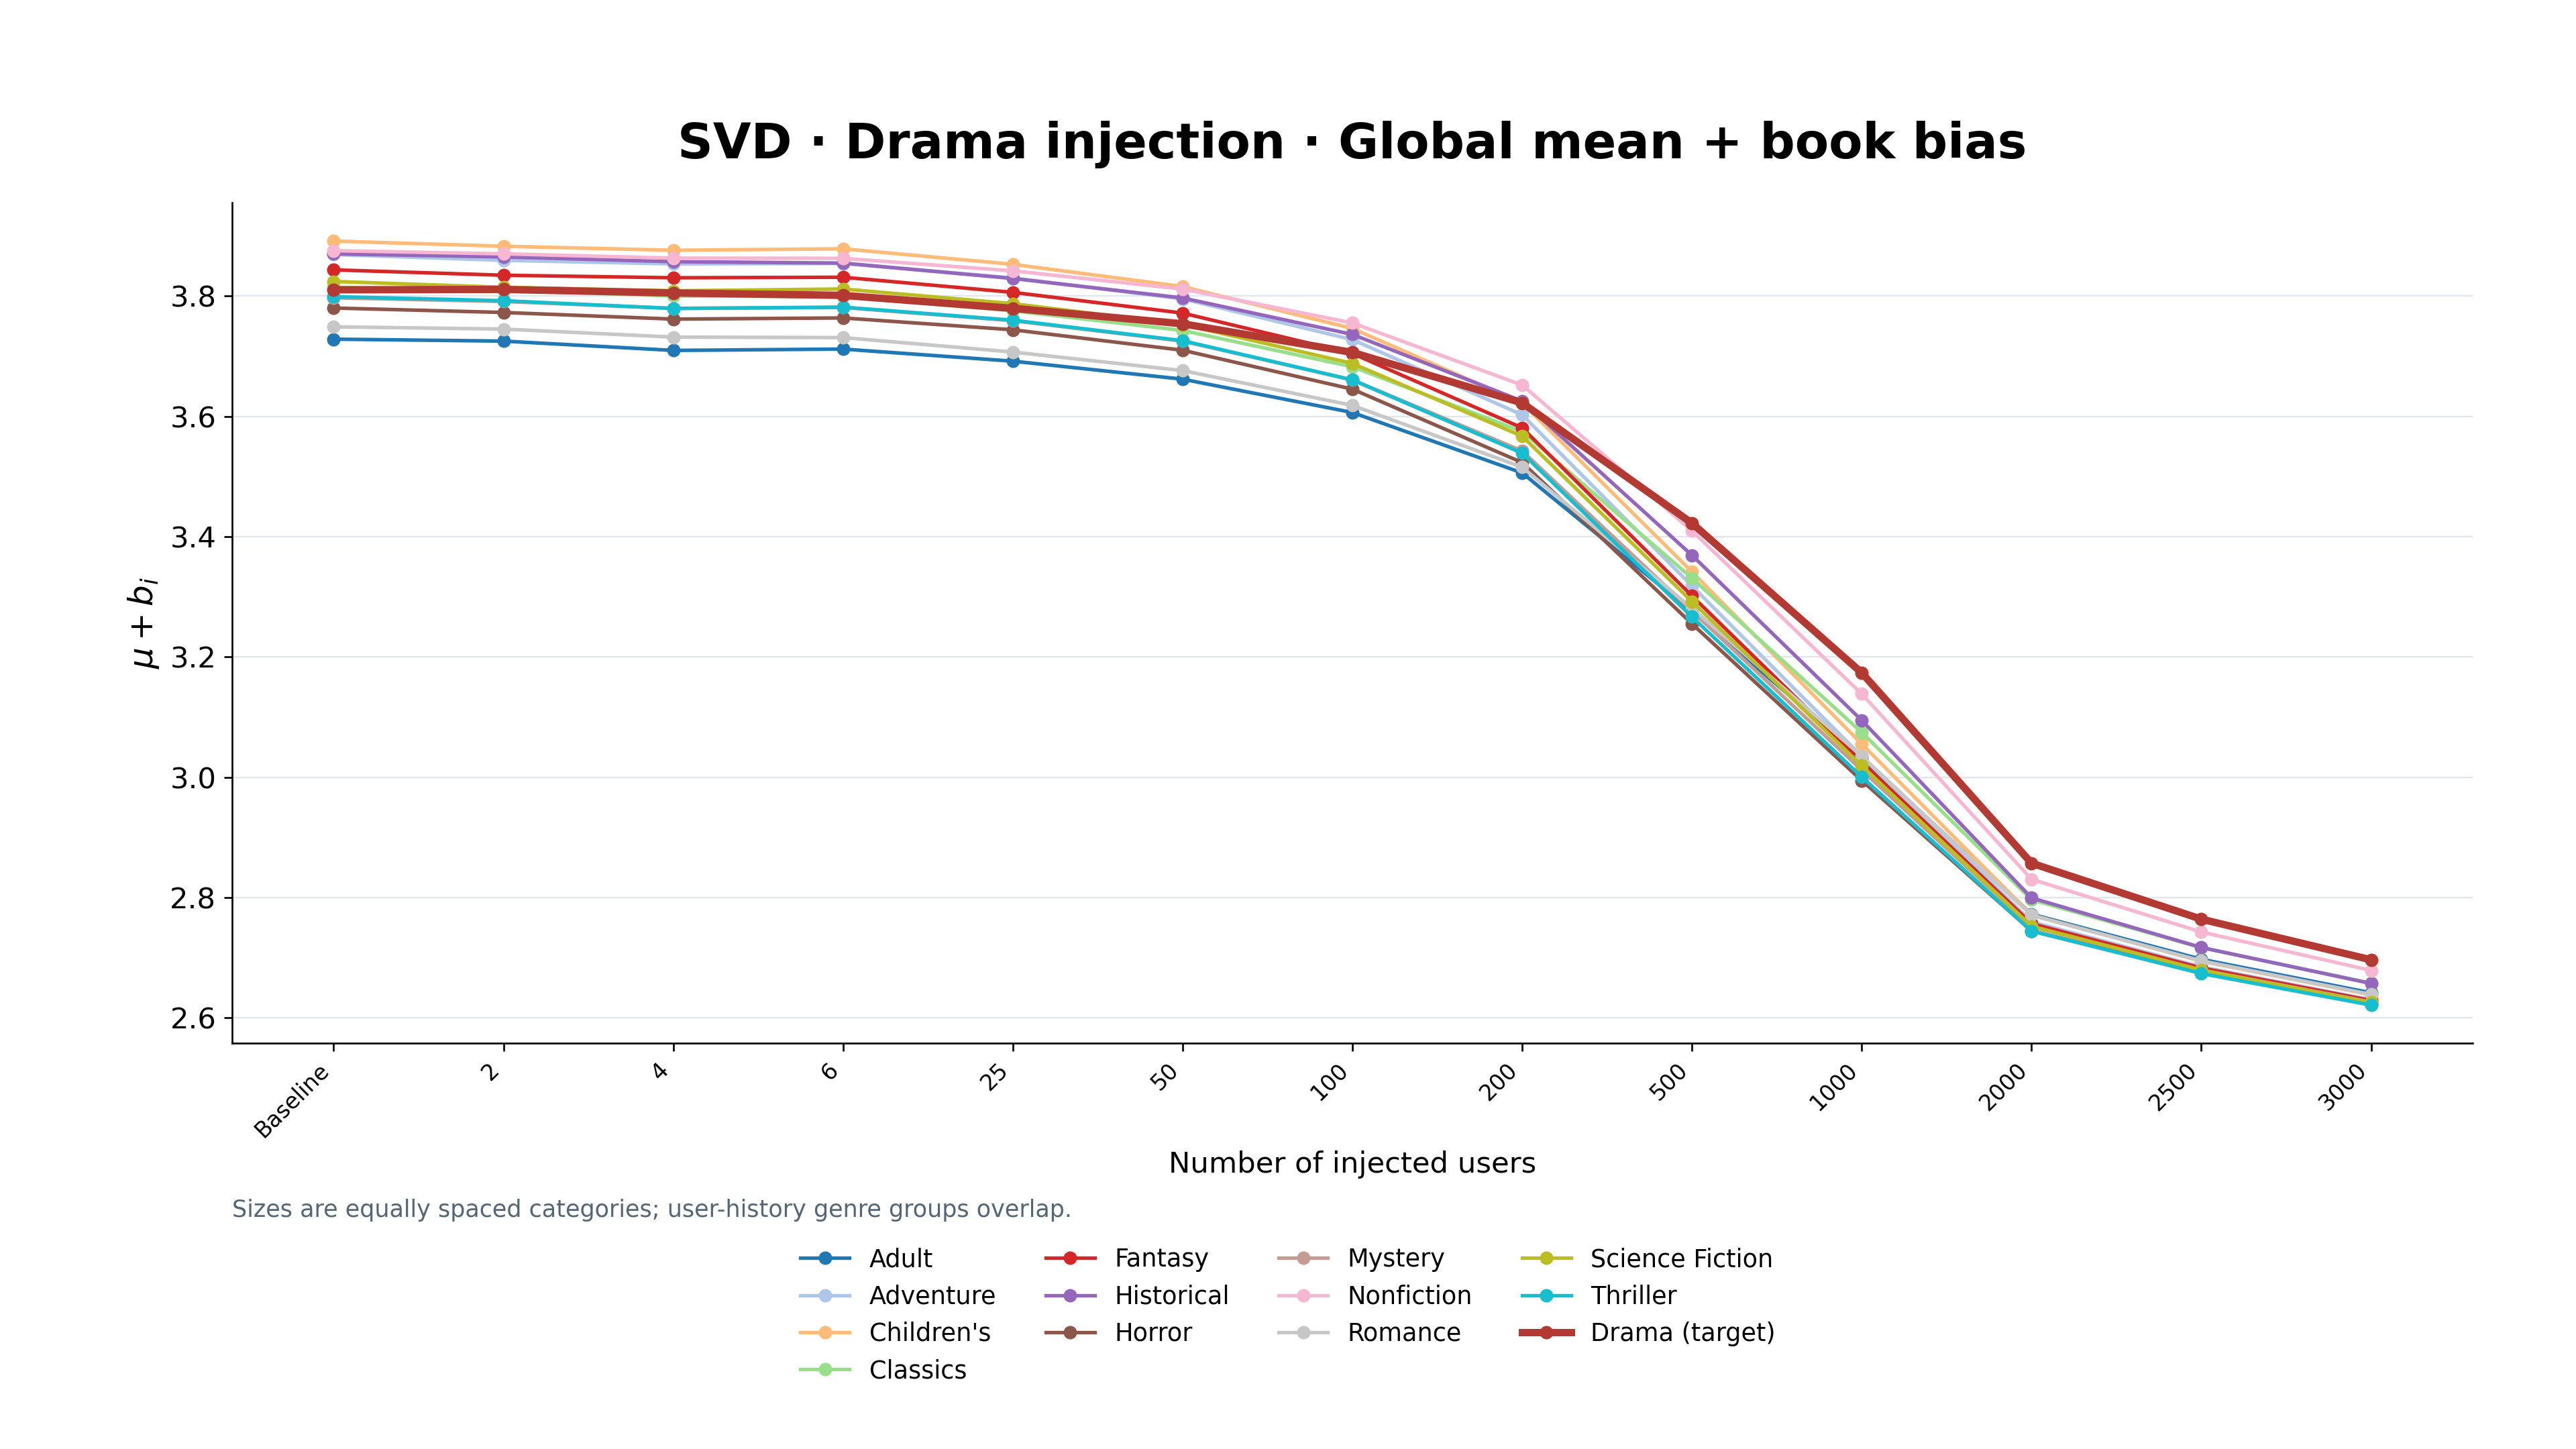

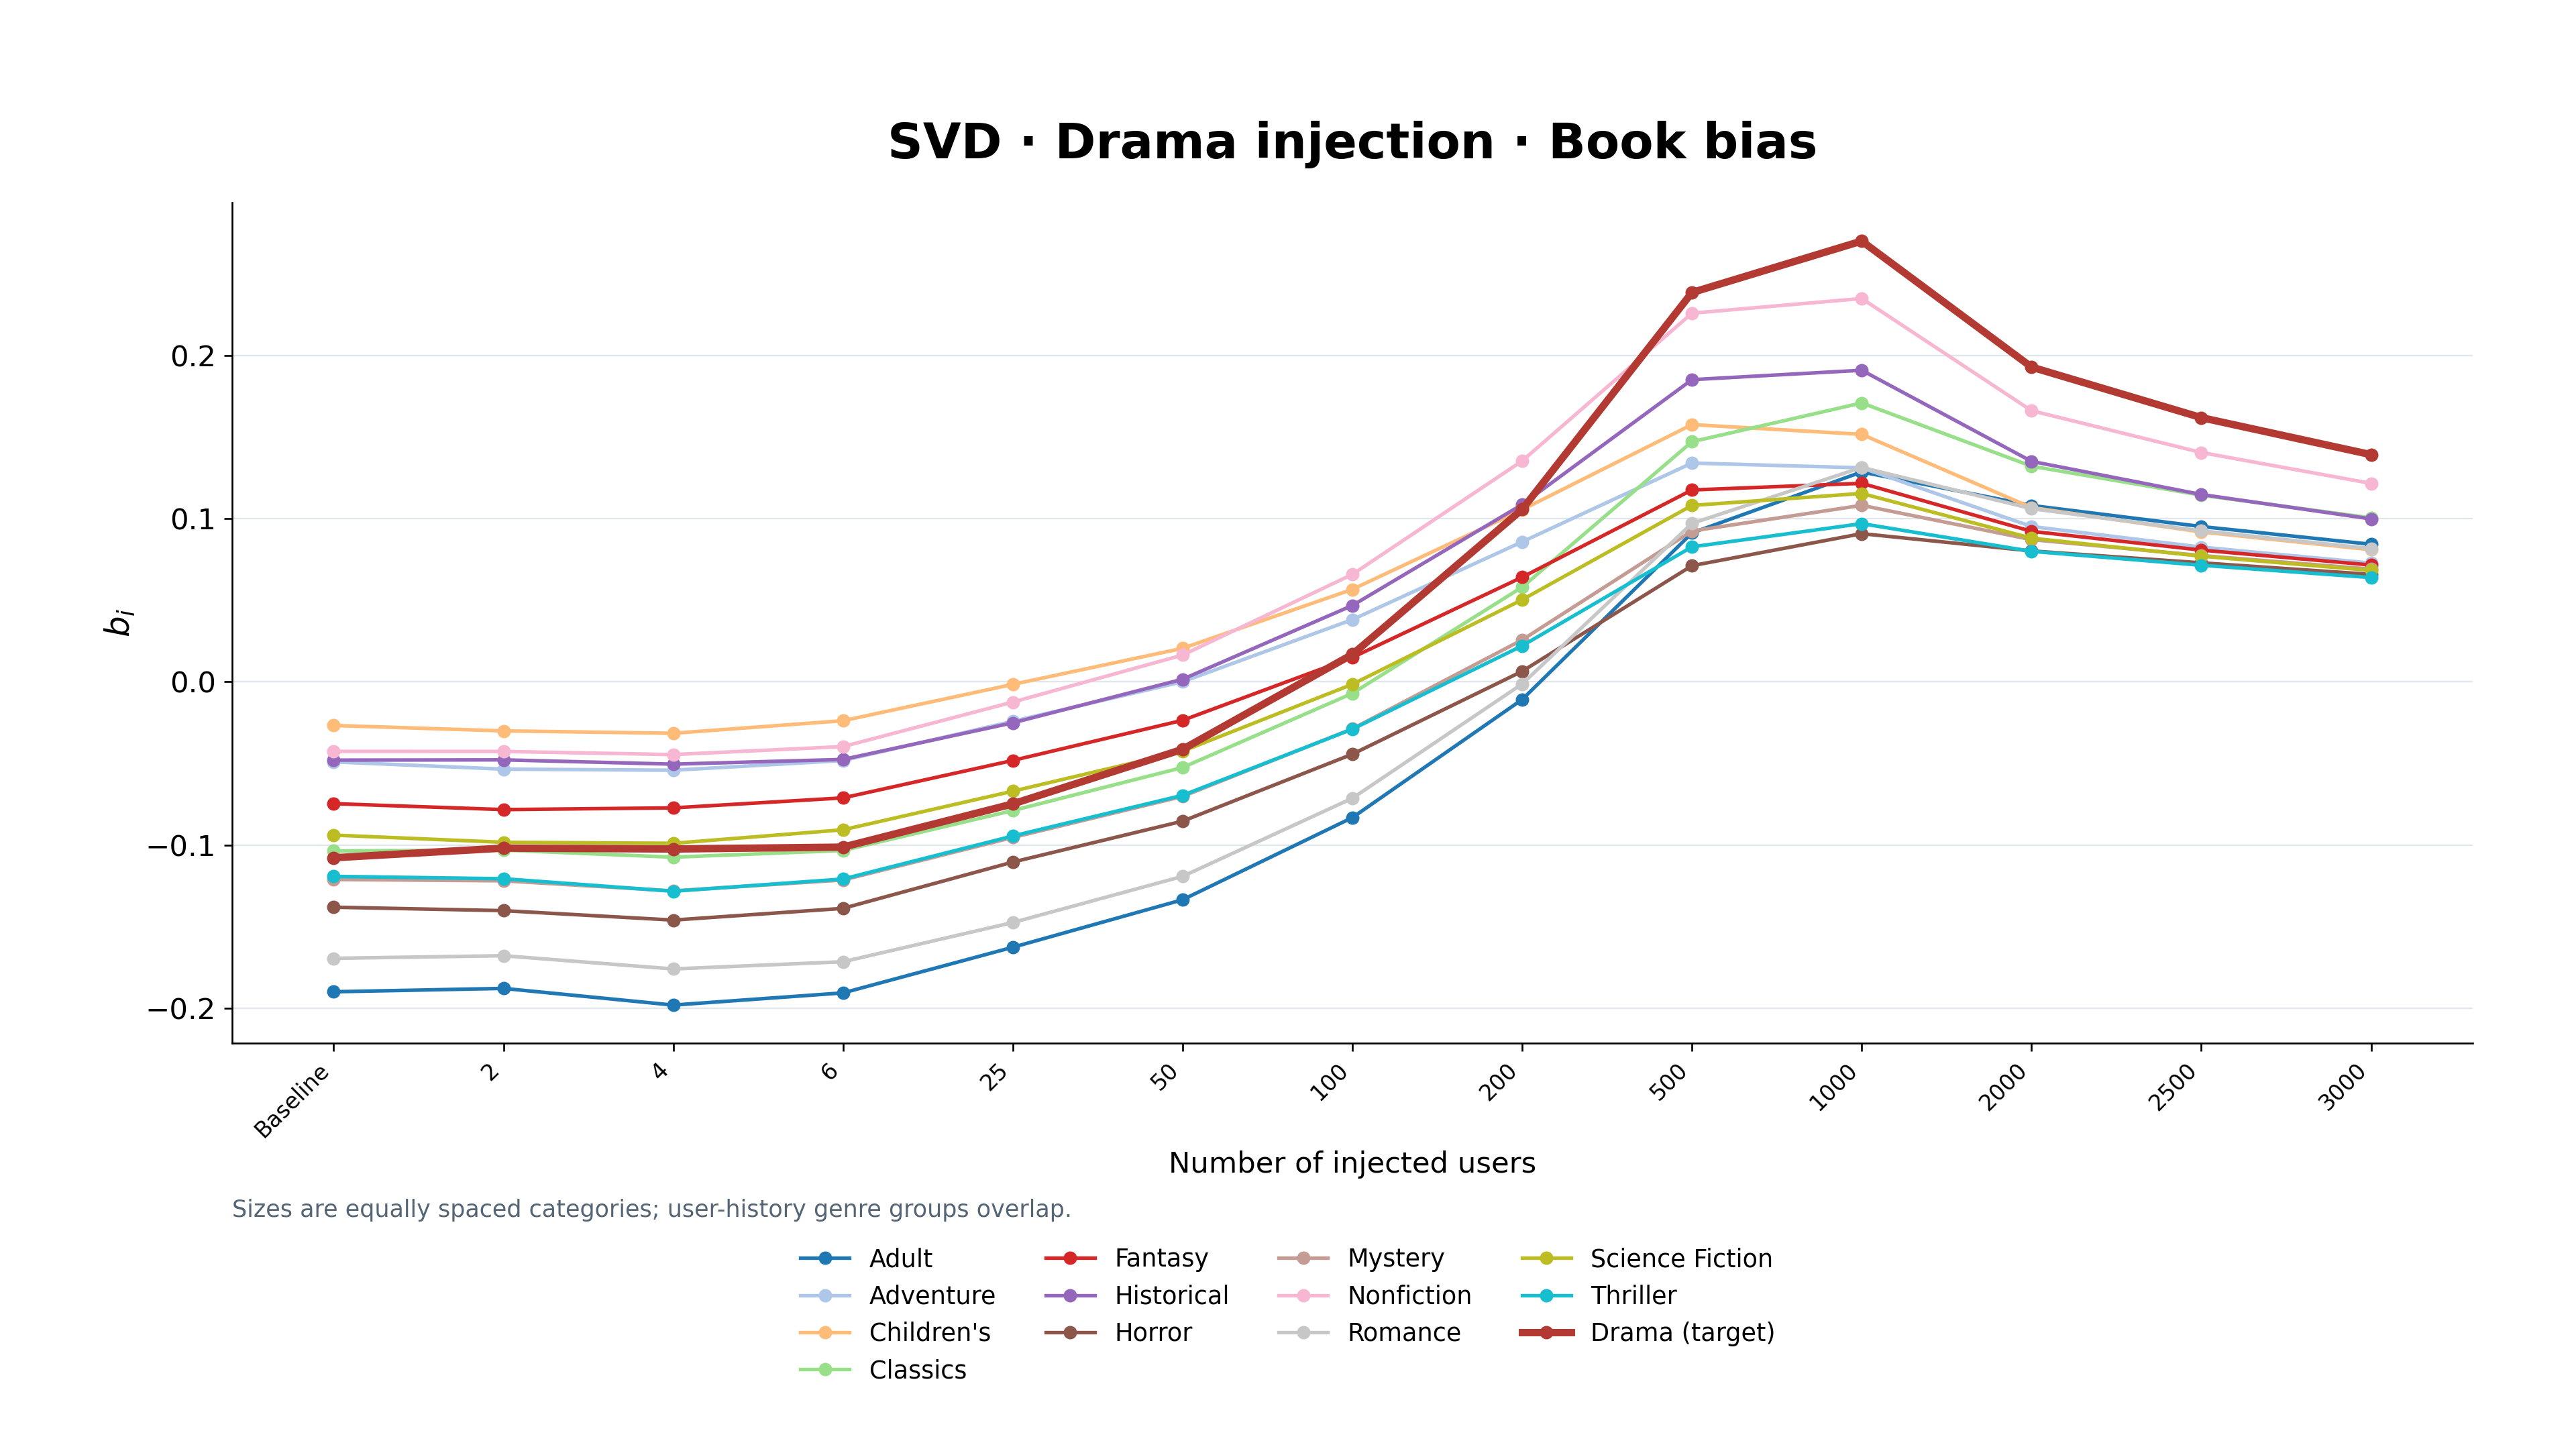

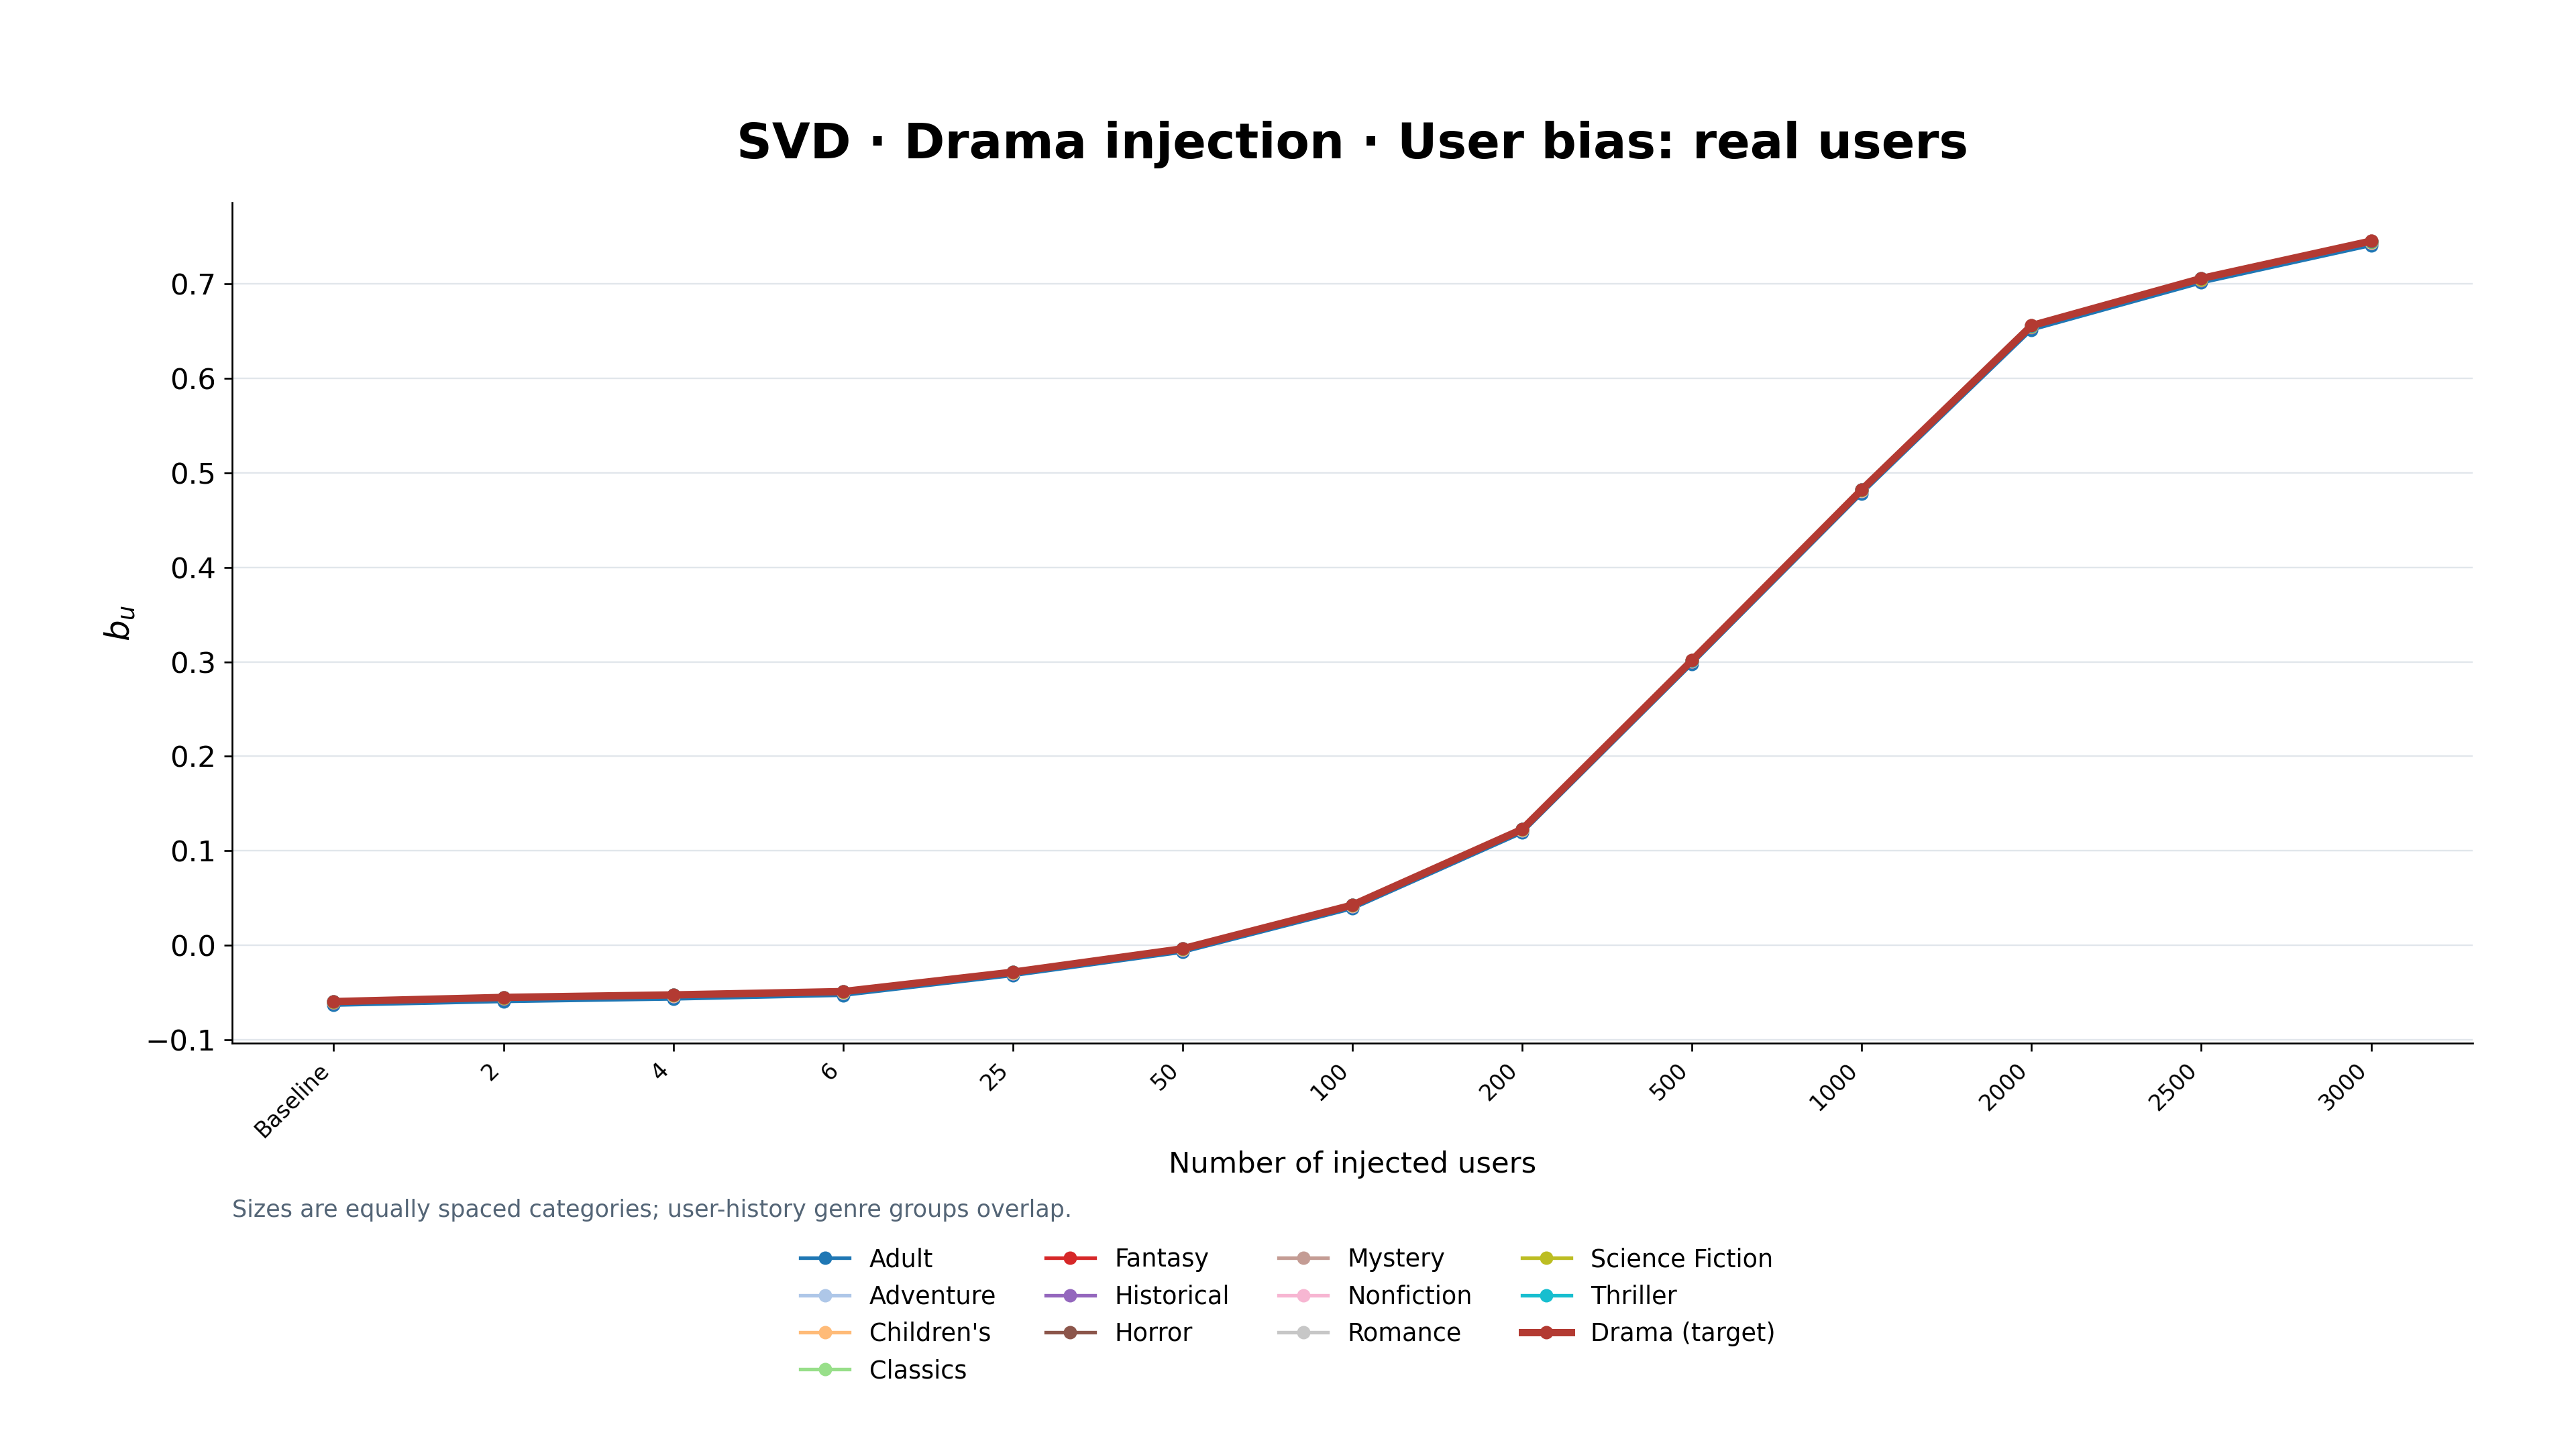

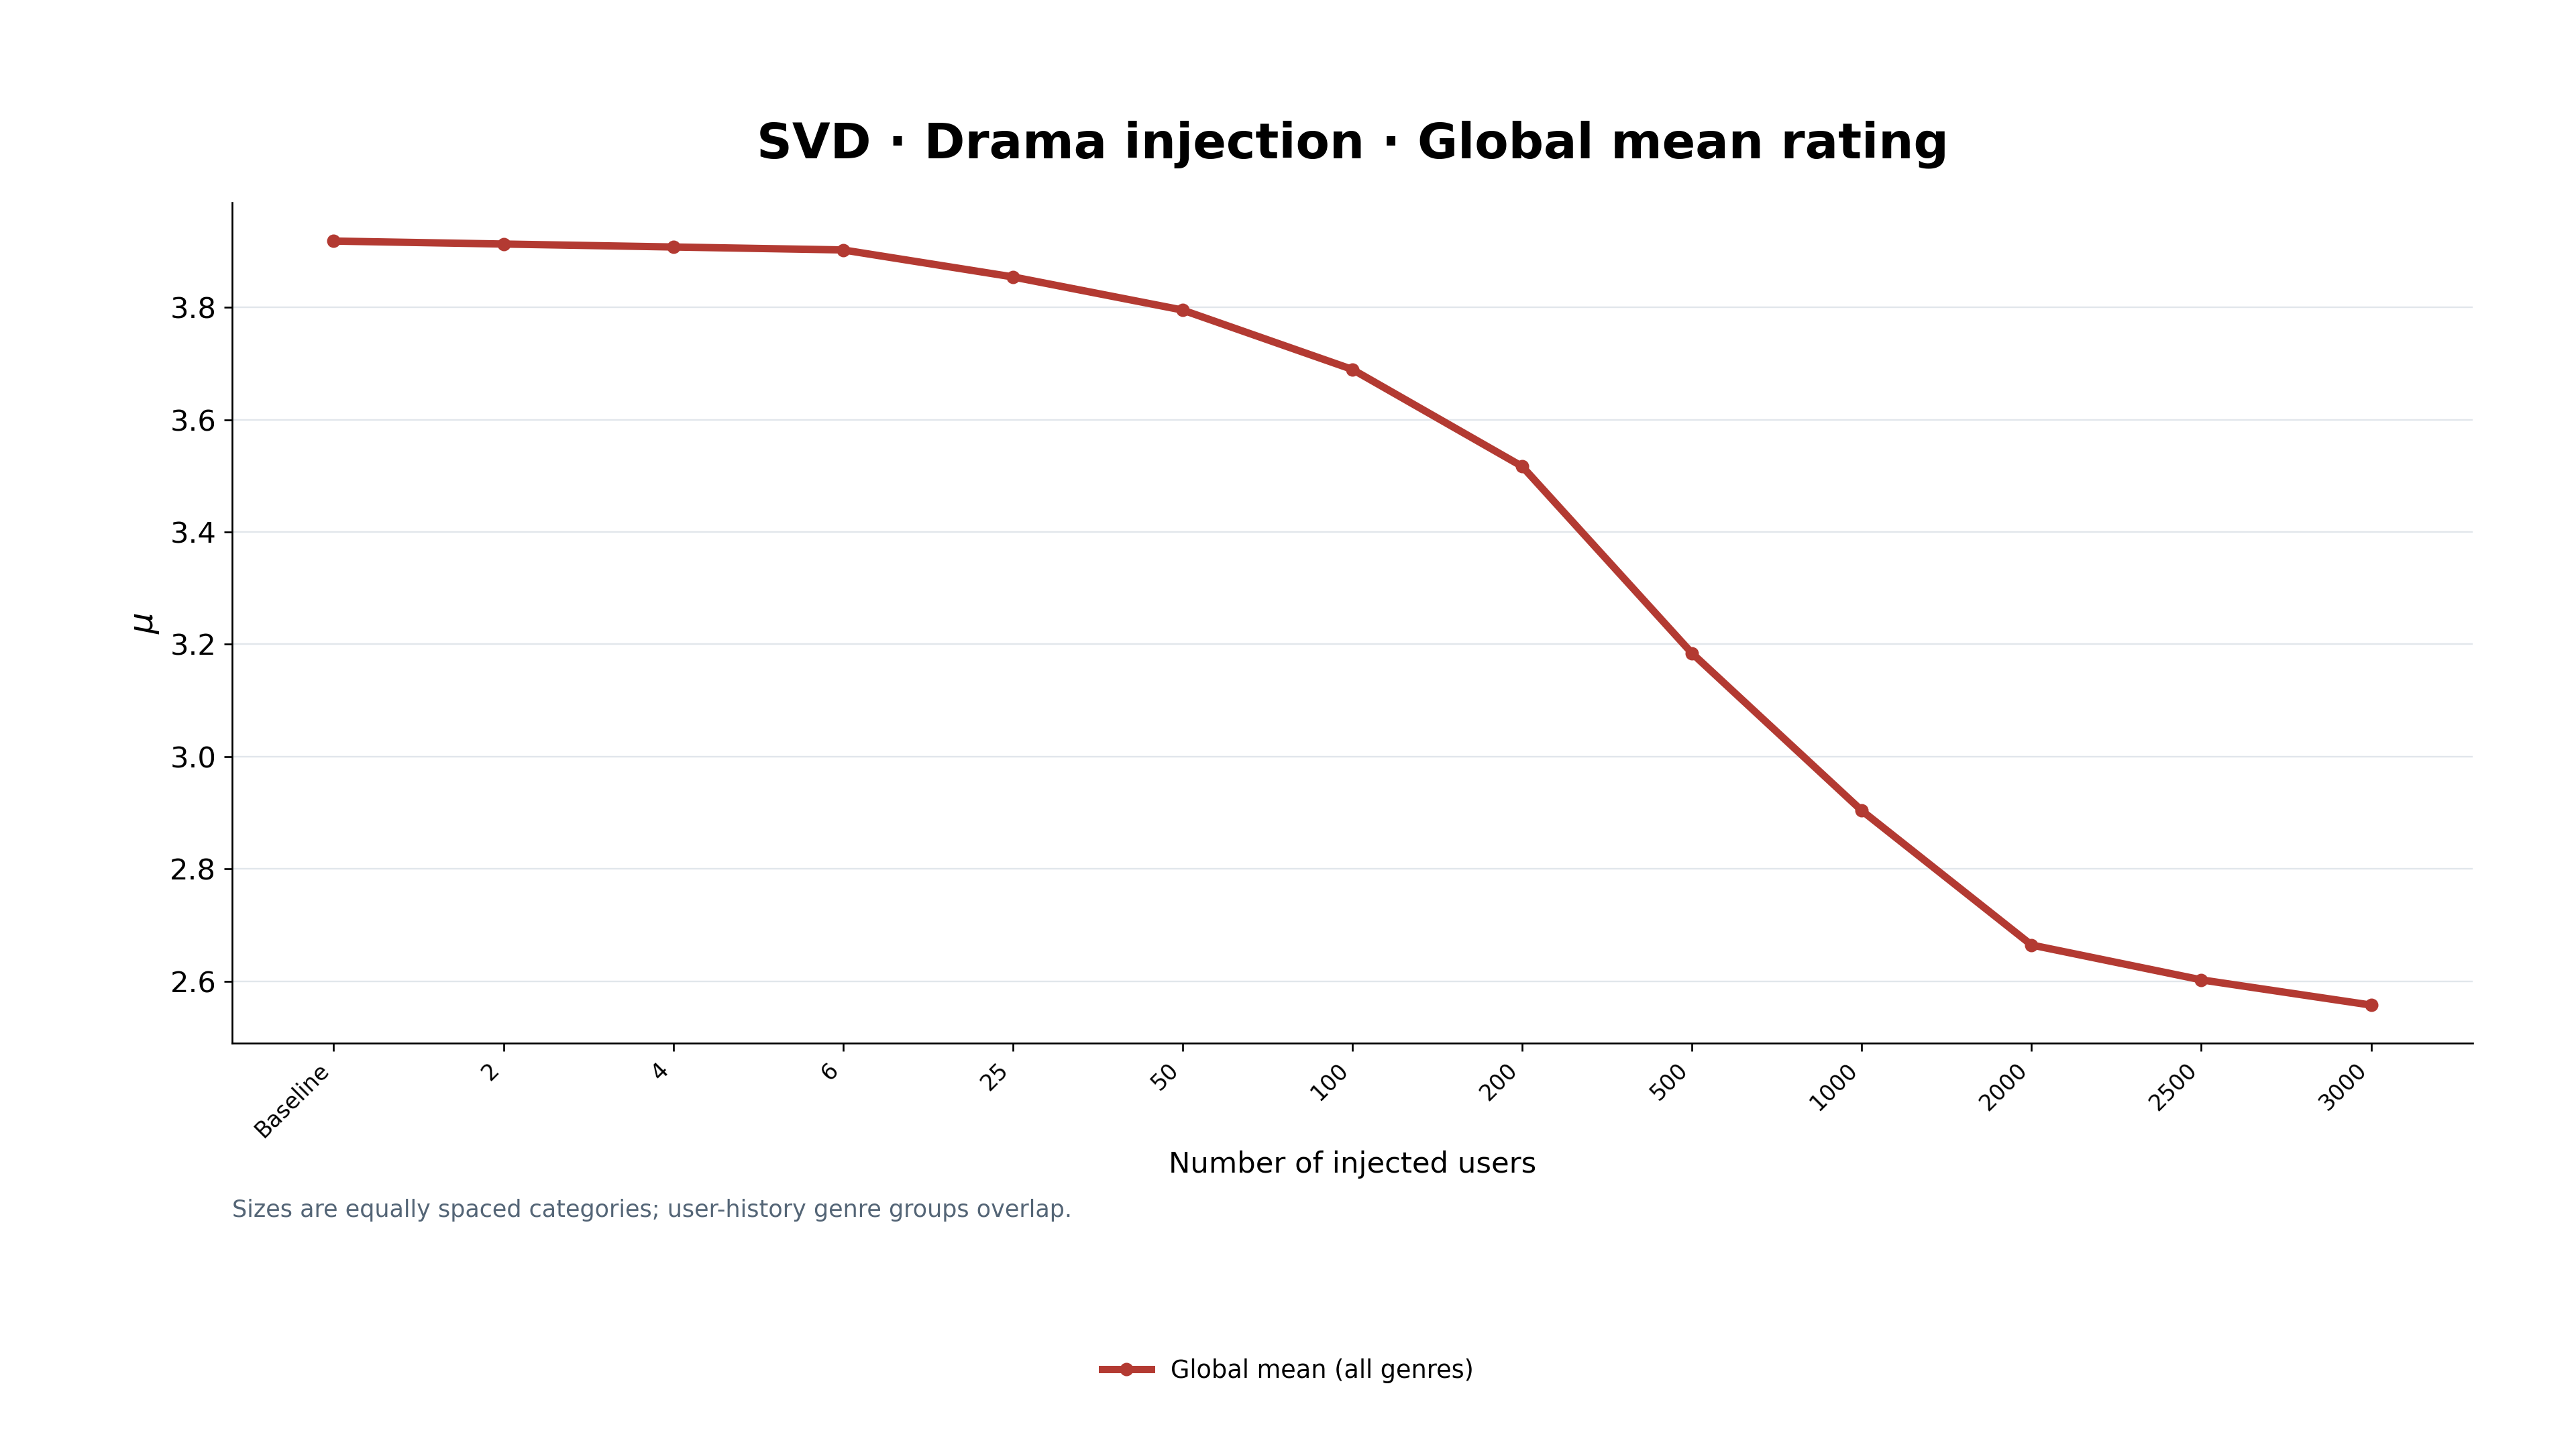

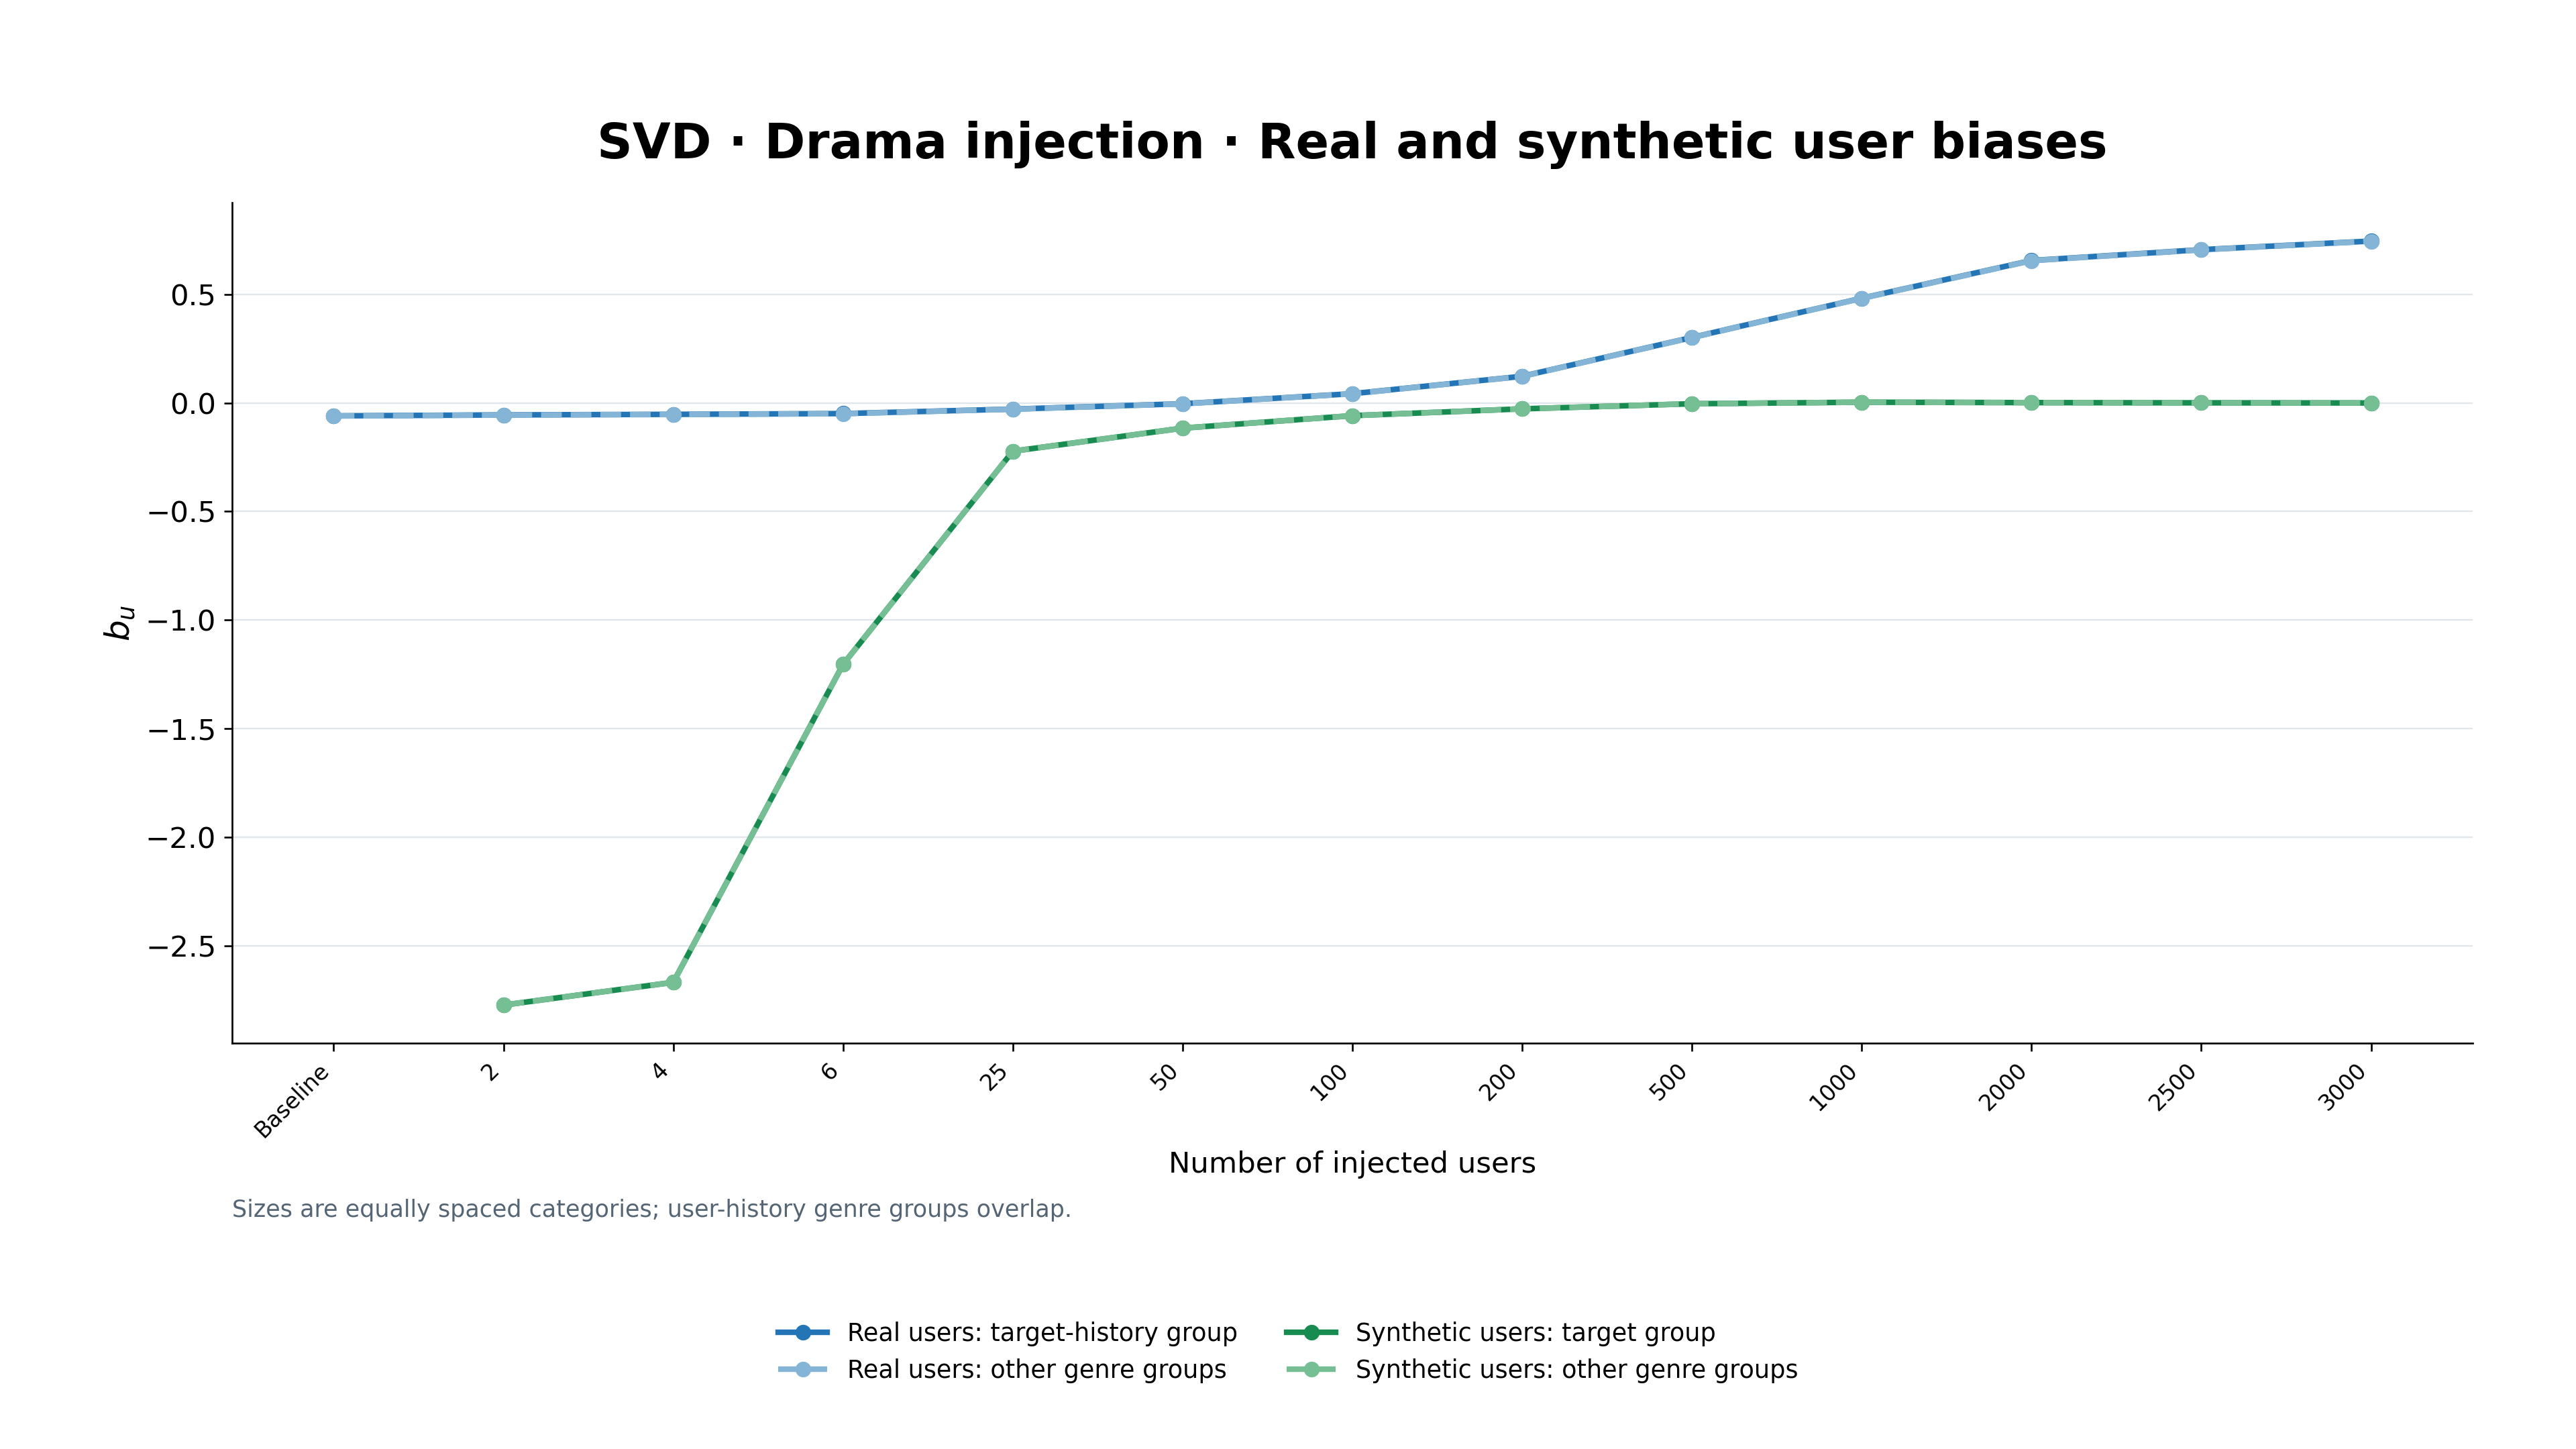

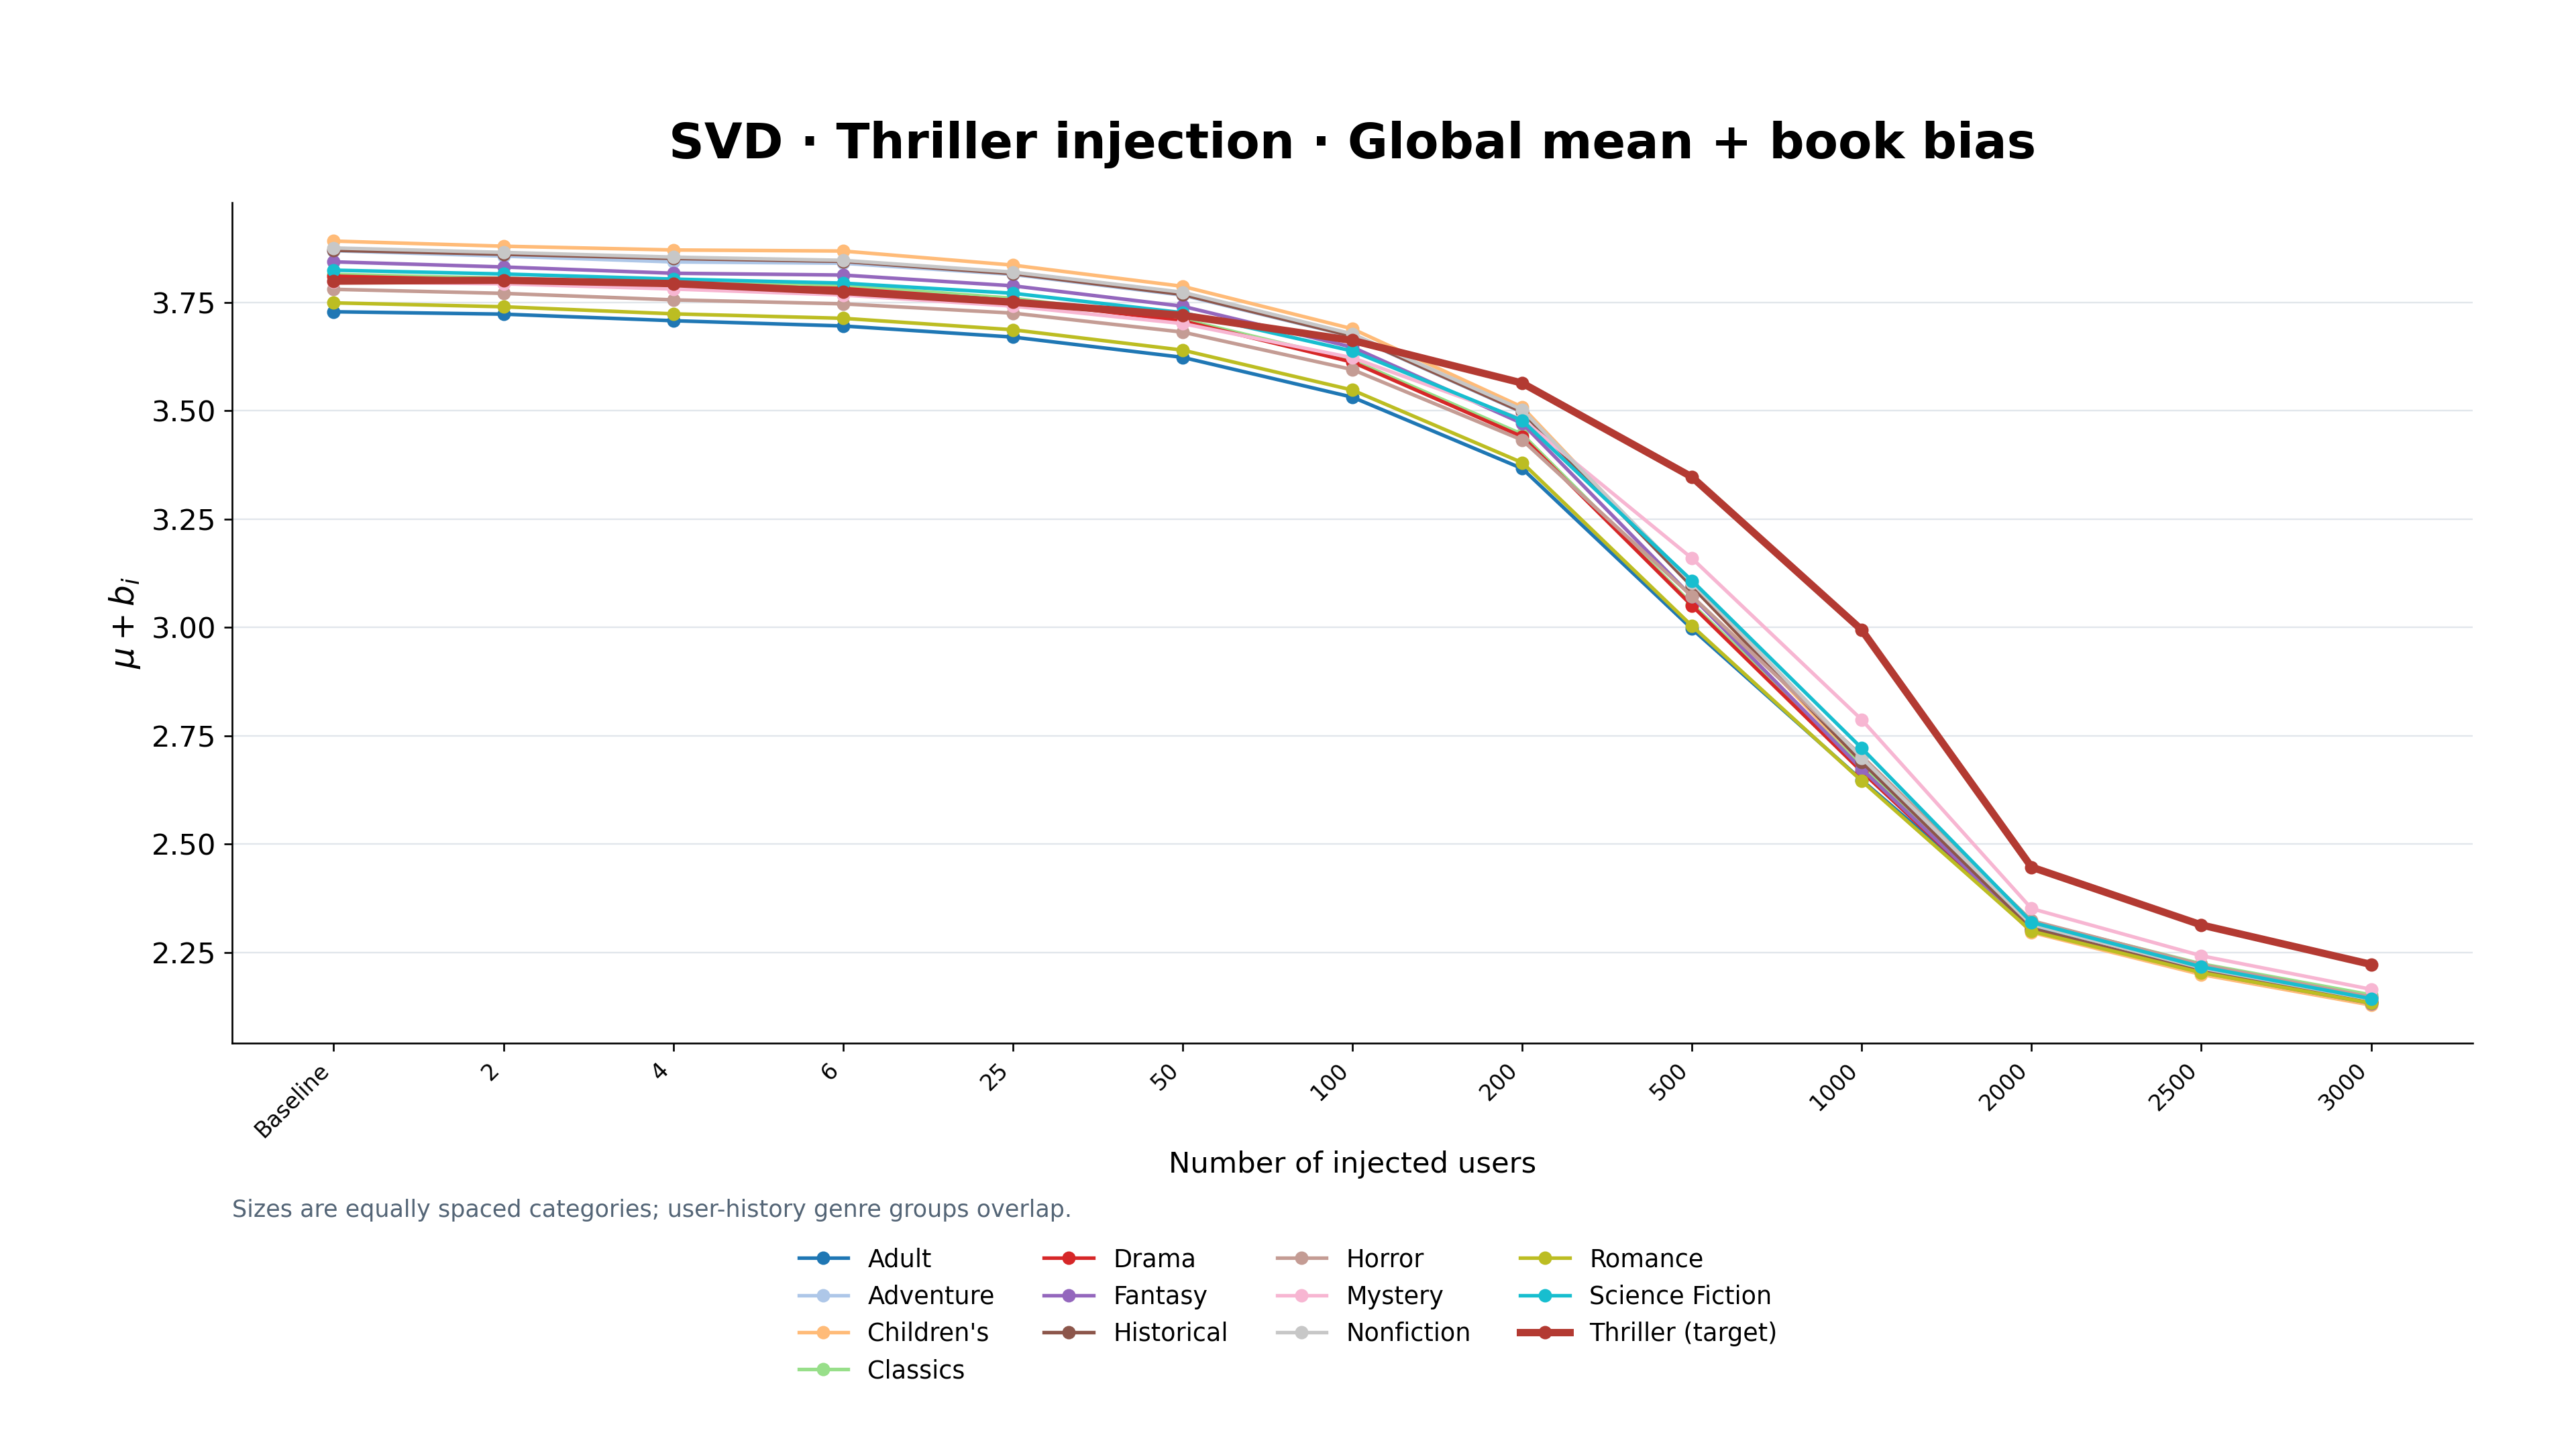

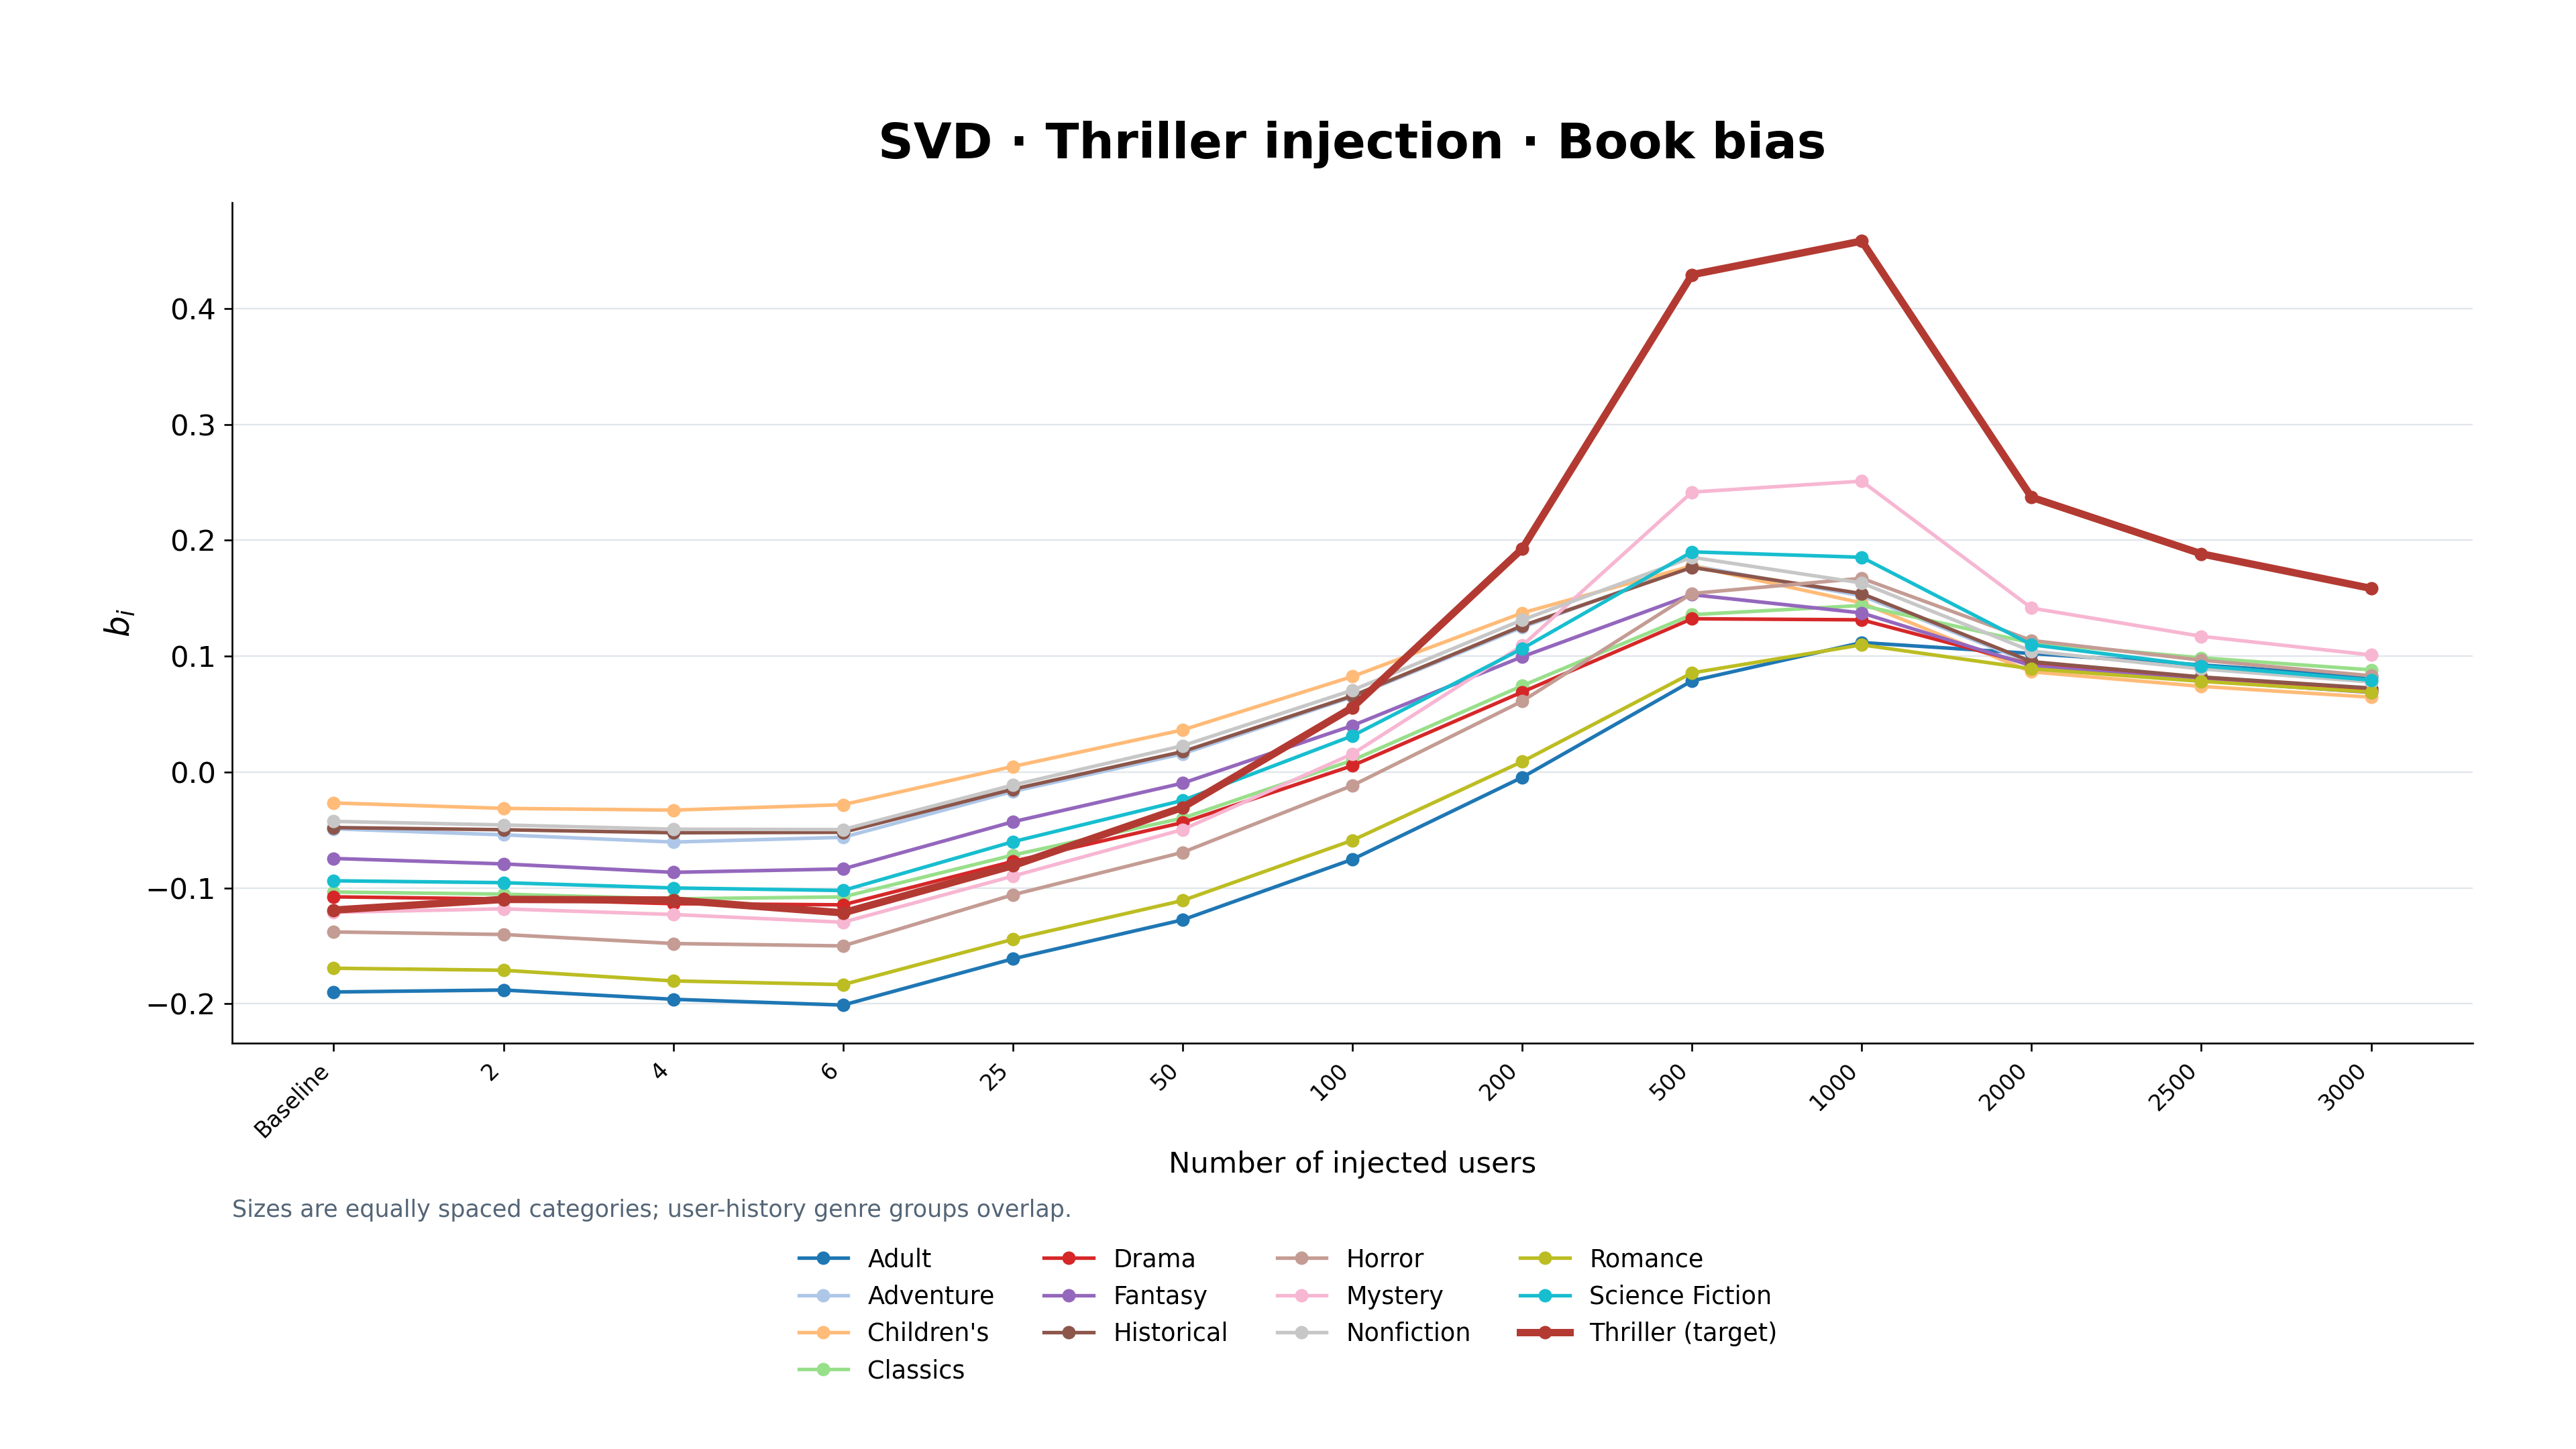

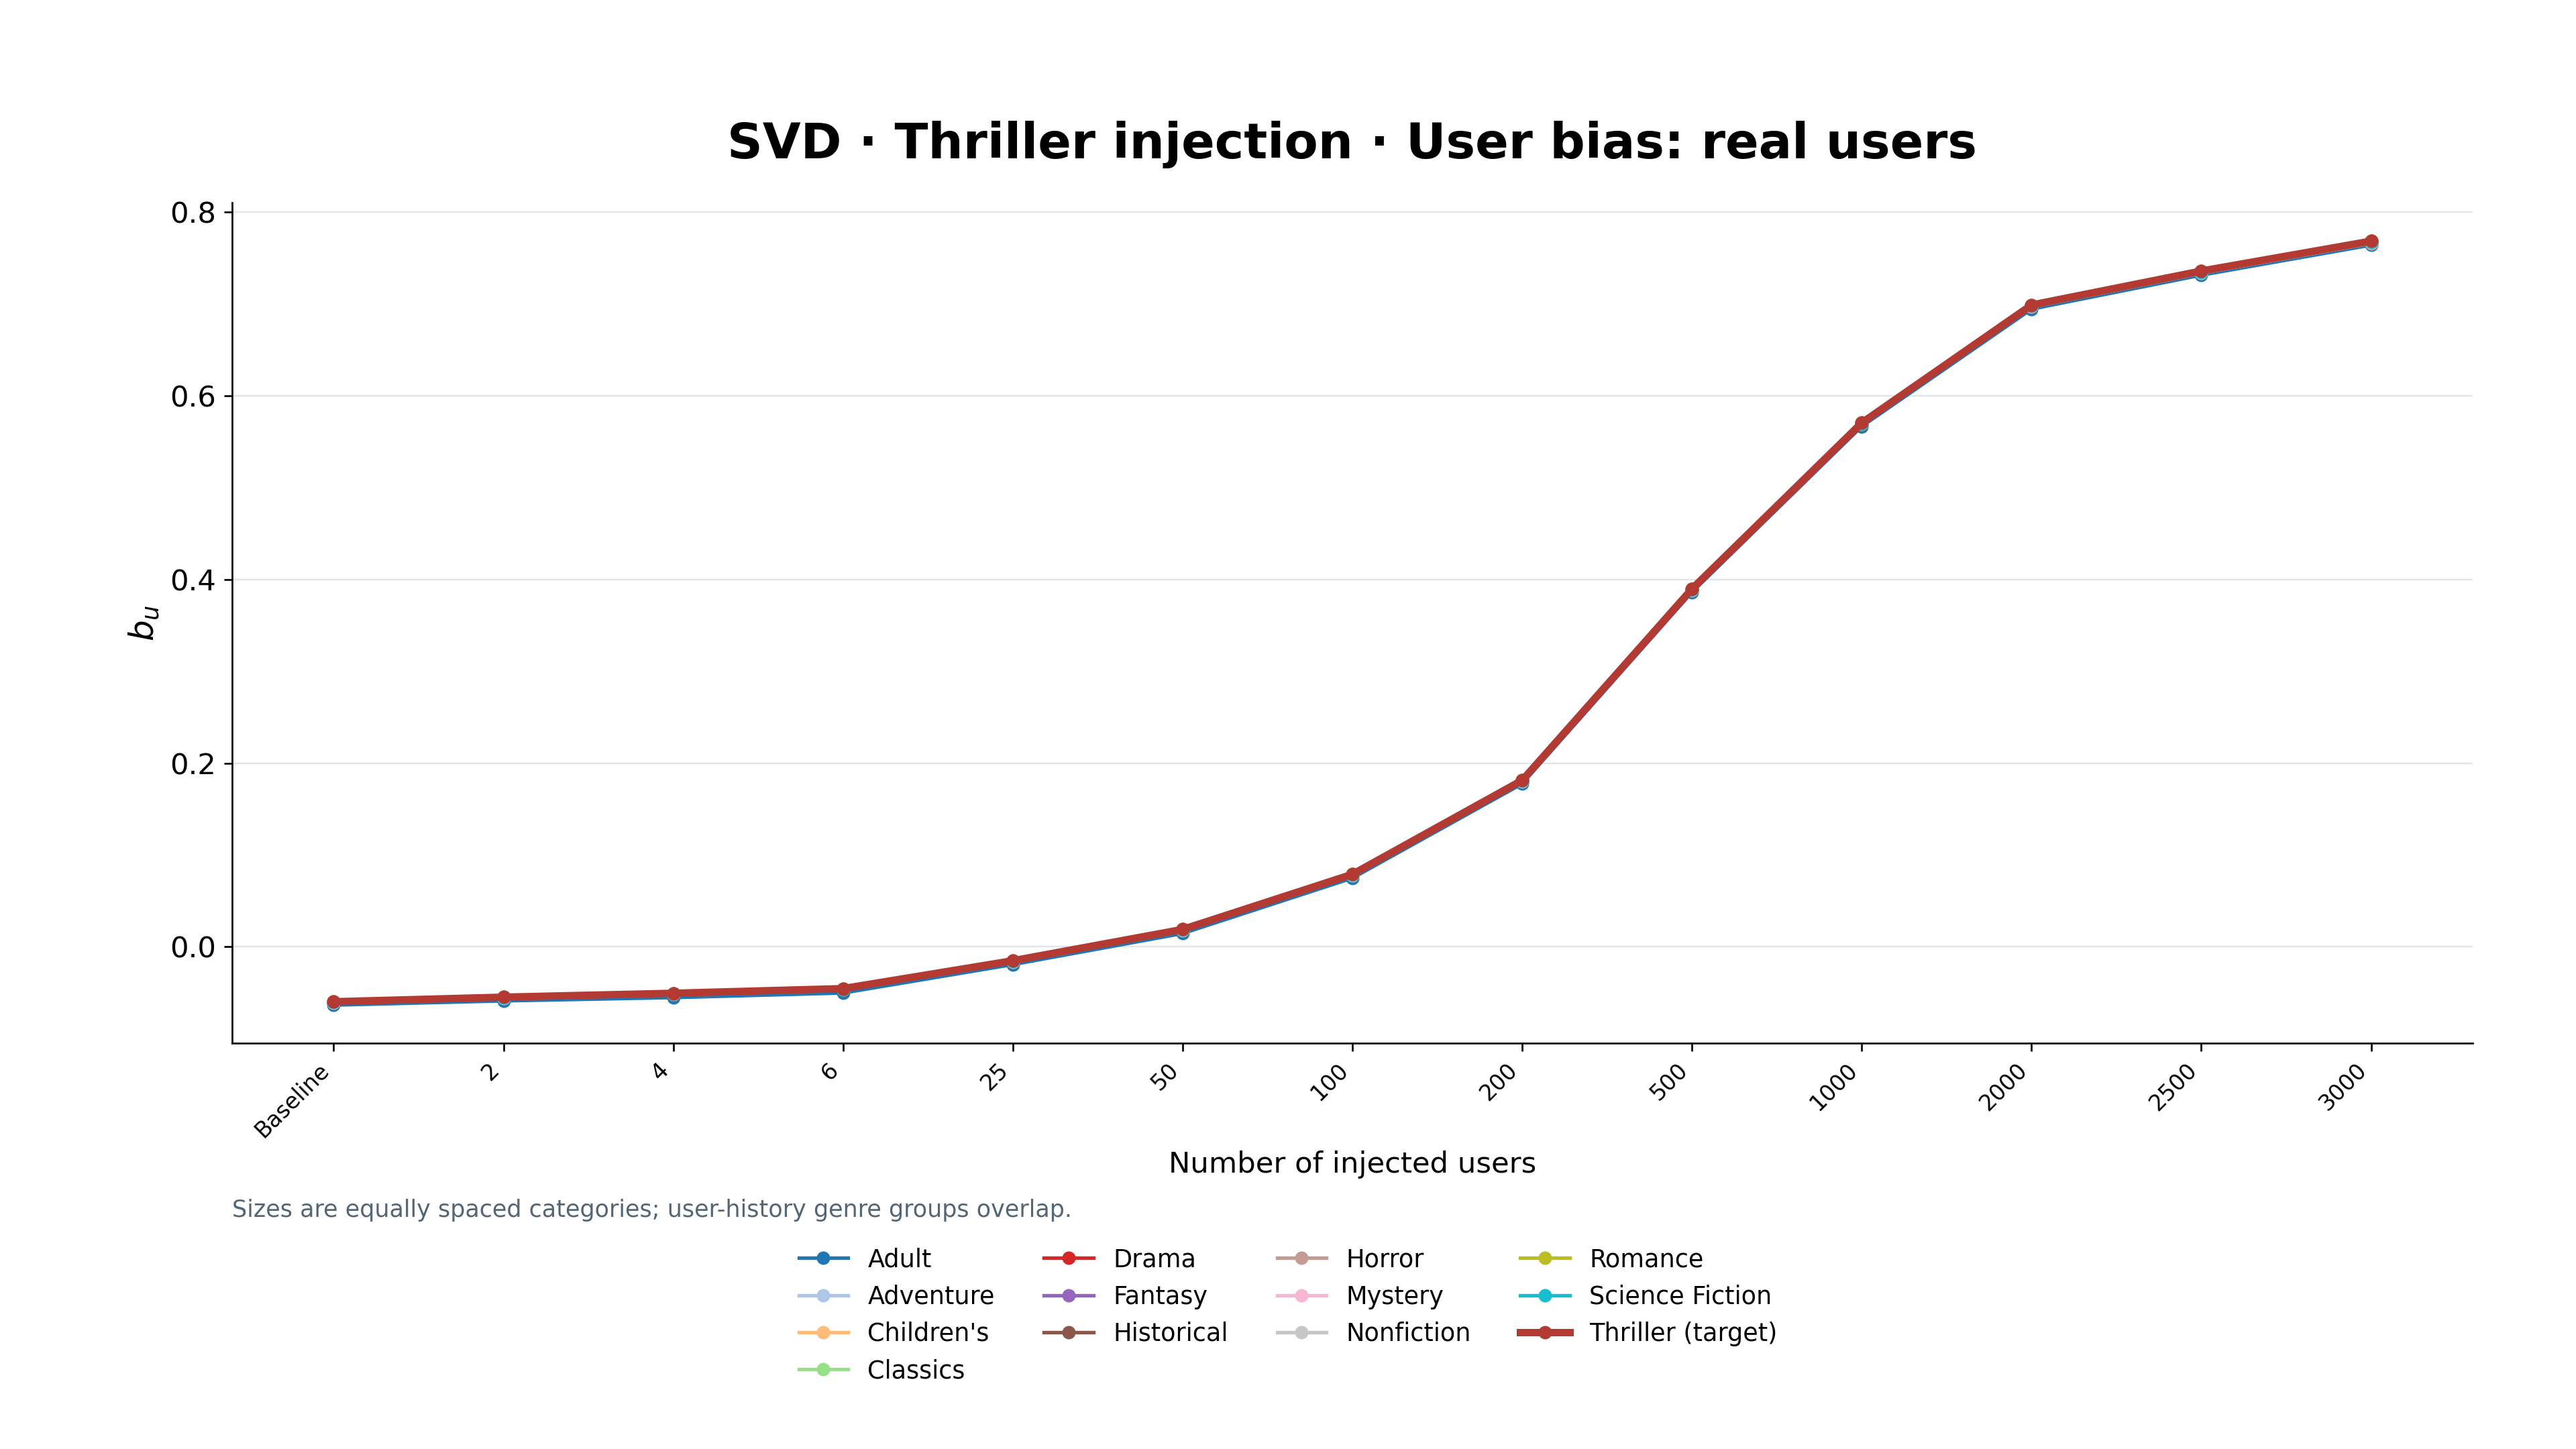

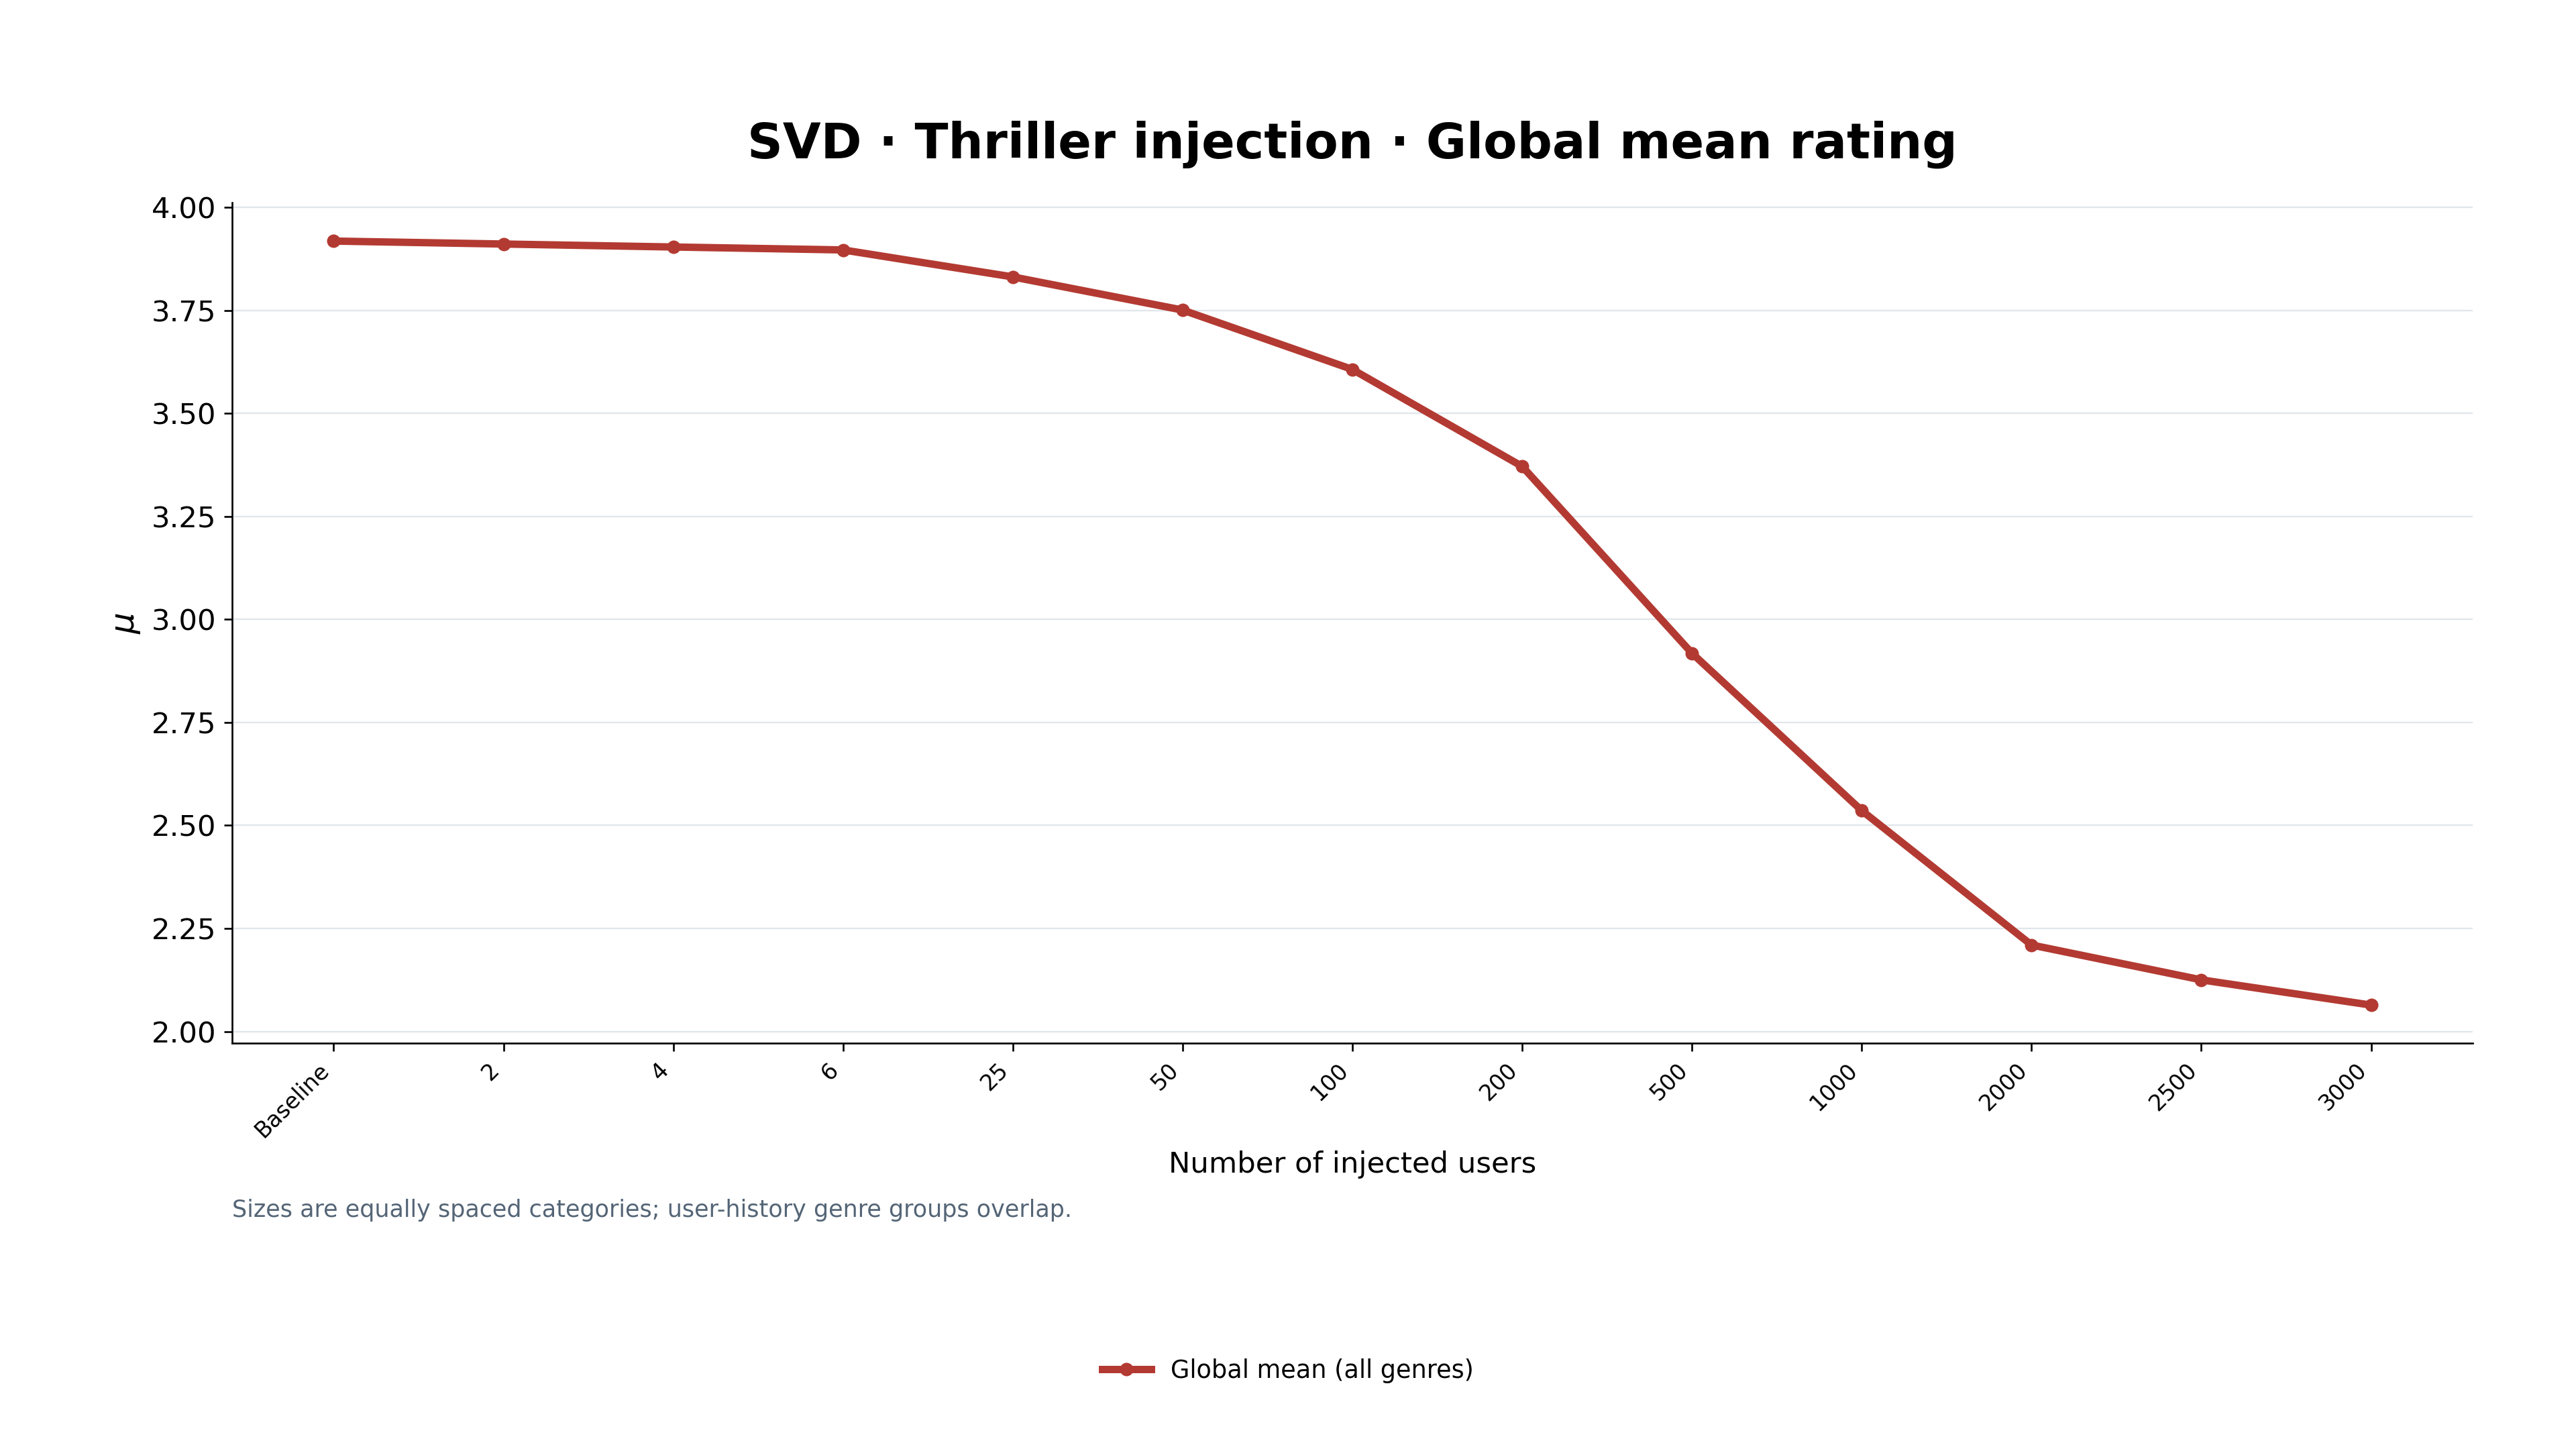

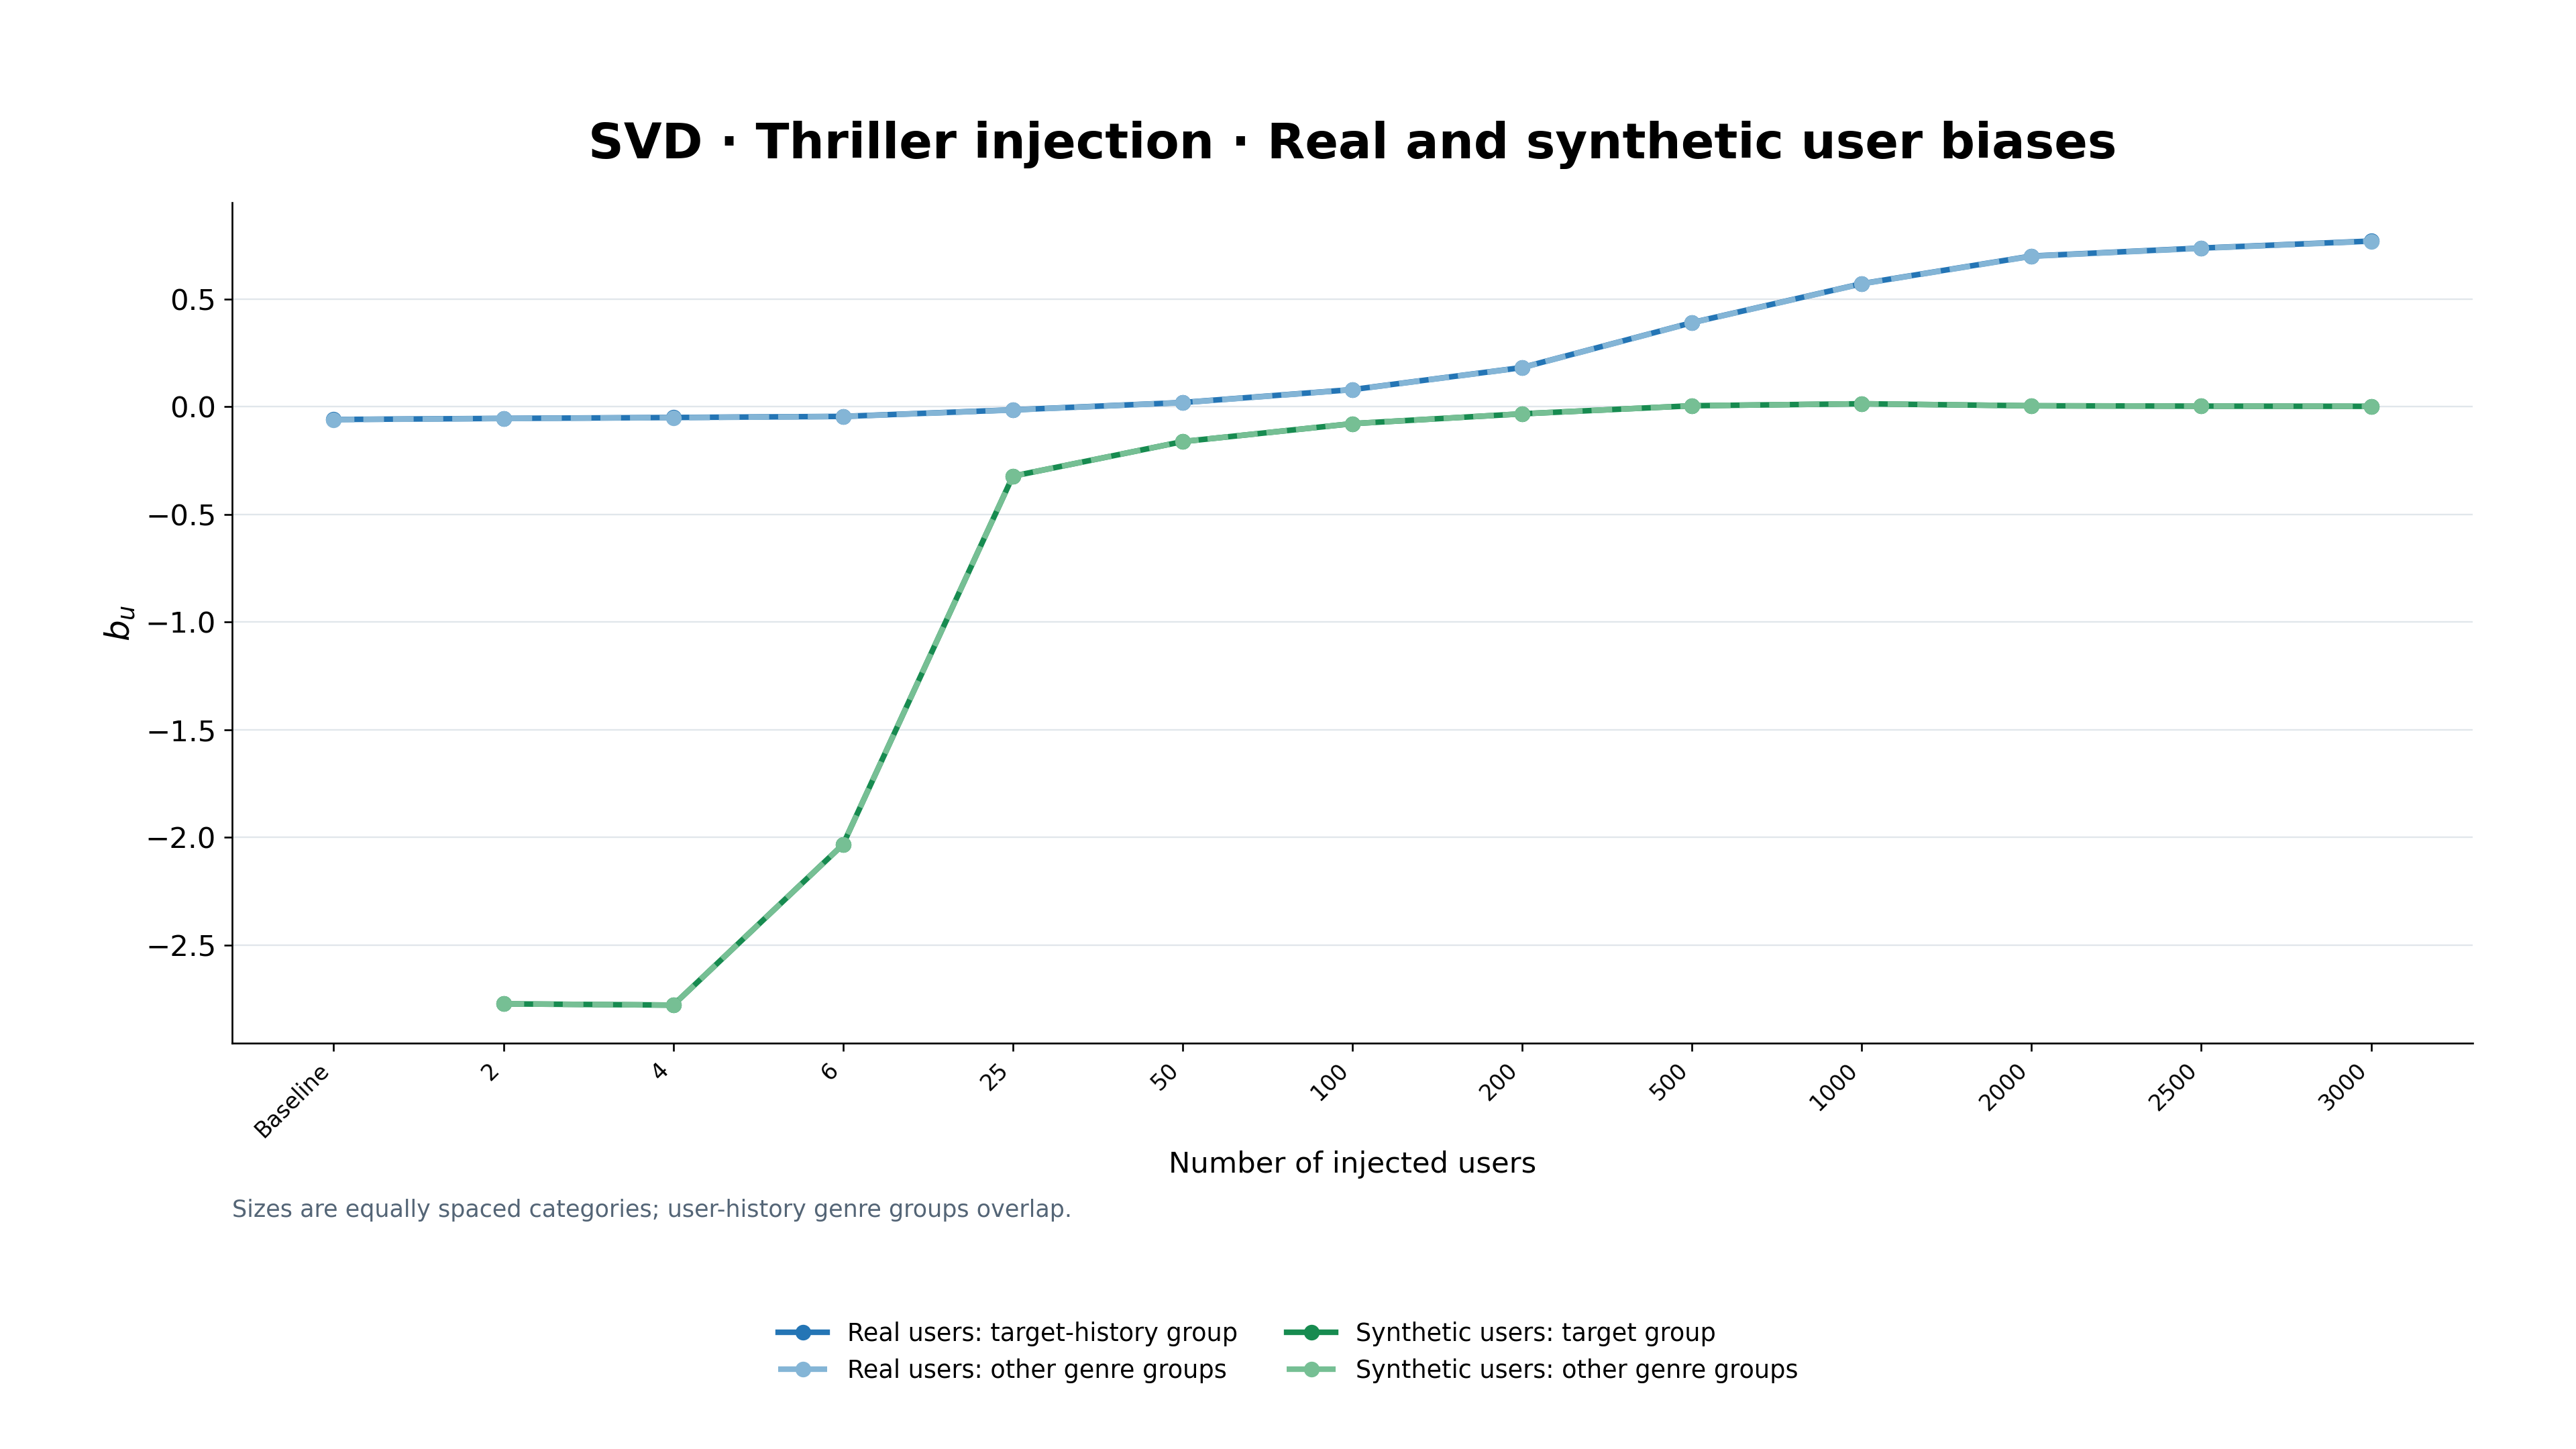

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path("/home/moshtasa/Research/phd-recsys/Book/current/PerturbRec/svd_nmf/layer1")
MODEL = "svd"
COUNTS = [0,2,4,6,25,50,100,200,500,1000,2000,2500,3000]
frames = []
for path in sorted((ROOT / "result" / MODEL / "merged").glob("*.csv")):
    frame = pd.read_csv(path)
    assert "n_fake" in frame.columns
    frames.append(frame)
data = pd.concat(frames, ignore_index=True)
genres = sorted(data.genre.unique())
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":13,
                    "axes.spines.top":False, "axes.spines.right":False})
metrics = [("mu_plus_bi","Global mean + book bias",r"$\mu+b_i$"),
           ("bi_only","Book bias",r"$b_i$"),
           ("bu_only_non_biasing","User bias: real users",r"$b_u$"),
           ("mu_only","Global mean rating",r"$\mu$"),
           ("bu_biased_vs_unbiased_target_vs_nontarget","Real and synthetic user biases",r"$b_u$")]
for target in ["Drama", "Thriller"]:
    d = data[(data.injected_genre==target) | (data.n_fake==0)]
    assert sorted(d.n_fake.unique()) == COUNTS
    for metric,title,ylabel in metrics:
        fig,ax=plt.subplots(figsize=(16,9))
        x=np.arange(len(COUNTS))
        if metric.startswith("bu_biased"):
            for kind,istarget,color,style,label in [
                ("non_biasing",True,"#2475B5","-","Real users: target-history group"),
                ("non_biasing",False,"#84B5D6","--","Real users: other genre groups"),
                ("biasing",True,"#178B50","-","Synthetic users: target group"),
                ("biasing",False,"#76BF94","--","Synthetic users: other genre groups")]:
                vals=[]
                for n in COUNTS:
                    part=d[(d.n_fake==n)&(d.user_type==kind)]
                    part=part[part.genre==target] if istarget else part[part.genre!=target]
                    vals.append(part.avg_bu.mean() if len(part) else np.nan)
                ax.plot(x,vals,style,marker="o",lw=2.5,color=color,label=label)
        else:
            labels=[target] if metric=="mu_only" else [g for g in genres if g!=target]+[target]
            palette=plt.cm.tab20(np.linspace(0,1,len(genres)))
            for j,g in enumerate(labels):
                part=d[(d.genre==g)&(d.user_type=="non_biasing")].sort_values("n_fake")
                assert part.n_fake.tolist()==COUNTS
                if metric=="mu_plus_bi":vals=part.global_mean_mu+part.avg_bi
                else:vals=part[{"bi_only":"avg_bi","bu_only_non_biasing":"avg_bu","mu_only":"global_mean_mu"}[metric]]
                color="#B33A32" if g==target else palette[j]
                label="Global mean (all genres)" if metric=="mu_only" else f"{g} (target)" if g==target else g
                ax.plot(x,vals,"-o",color=color,lw=3.3 if g==target else 1.6,ms=5,label=label)
        ax.set_title(f"{MODEL.upper()} · {target} injection · {title}",fontsize=22,weight="bold",pad=20)
        ax.set_xticks(x);ax.set_xticklabels(["Baseline"]+list(map(str,COUNTS[1:])),rotation=45,ha="right",fontsize=10)
        ax.set_xlabel("Number of injected users",fontsize=13);ax.set_ylabel(ylabel,fontsize=15)
        ax.grid(axis="y",color="#E1E6EB",lw=.7)
        handles,names=ax.get_legend_handles_labels()
        fig.legend(handles,names,loc="lower center",bbox_to_anchor=(.5,.03),ncol=4 if len(names)>4 else 2,frameon=False,fontsize=11)
        fig.subplots_adjust(left=.09,right=.96,bottom=.28,top=.86)
        fig.text(.09,.16,"Sizes are equally spaced categories; user-history genre groups overlap.",fontsize=10.5,color="#546576")
        figure_dir = ROOT / "result" / MODEL / f"{MODEL.upper()}_details_figures" / target
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_dir / f"{metric}.png", dpi=240, facecolor="white")
        plt.show()
        plt.close(fig)
